# Testing optic-flow vs. vectorial encoding in marching locusts

This notebook revisits and re-analyzes one set of the virtual-reality experiments of S. Sayin et al., "The behavioral mechanisms governing collective motion in swarming locusts," *Science* **387**(6737), 995-1000 (2025); [doi:10.1126/science.adq7832](https://doi.org/10.1126/science.adq7832): it fits a **hierarchical mixture-of-two-von Mises** model to the heading decisions of **52 juvenile desert locusts** (2435 observed "steps" total) that marched on a motion-compensating ball inside a panoramic virtual-reality arena, viewing moving **virtual conspecifics** placed symmetrically at a lateral distance of 8 or 50 cm. Each row of the step table is one discretized heading decision (radians, $-\pi$ to $\pi$) of one animal, with $0$ pointing forward along the global march direction; the raw per-animal recordings come from [`jgraving/unwrap-data`](https://github.com/jgraving/unwrap-data) and the first data cell runs the rediscretization pipeline that produces this table.

**Why a mixture?**  In the VR task, two moving virtual swarms were positioned symmetrically at the animal's flanks, and the behavioral readout is the *full distribution* of headings. Two mechanistic hypotheses were proposed for how this local motion drives directional choice:

- **optic–flow / optomotor** — the animal aligns with the wide-field motion and keeps
  marching forward (heading near $0$);
- **vectorial / ring-attractor** — the animal treats the flanks as spatial targets and
  bifurcates left or right to join them (headings near $\pm\tfrac{\pi}{2}$).

A single von Mises mode cannot express both attractors at once. The bimodal mixture gives
each animal two preferred directions with their own concentrations and a mixing weight
(a sigmoid rather than a softmax link), and the hierarchical layer partially pools
parameters across the 52 animals so that sparsely sampled animals (3 to 204 steps per
animal) are shrunk toward the population mixture.

The mixture and its unimodal baseline are fit with `brms` custom Stan
likelihoods, with explicit priors on the circular coefficient vectors
keeping every direction on the circle.


## Setup

Select the **R (`ir`)** kernel after following the [R setup](../getting-started-r.md)
page; the setup cell stops with a pointer there if the pinned packages
or CmdStan are not available.

Run the cells in order from `notebooks_r/` or the repository root.

Running the notebook records versions, diagnostics, inline PNGs, and vector PDFs.


In [1]:
# Setup: check that this notebook's stack is available. The examples
# are verified against the pinned package set recorded in renv.lock, so
# this cell deliberately does not auto-install: an unpinned install
# could silently drift from the verified set. Run the one-time setup on
# the R setup page first (docs/getting-started-r.md).

required <- c("brms", "posterior", "loo", "arrow", "circular",
              "ggplot2", "patchwork", "ragg", "IRdisplay")
missing <- required[!vapply(required, requireNamespace, logical(1),
  quietly = TRUE)]
if (length(missing))
  stop("Missing R package(s): ", paste(missing, collapse = ", "),
       " - run the one-time setup on the R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

cmdstan_ok <- tryCatch(
  dir.exists(as.character(cmdstanr::cmdstan_path())),
  error = function(e) FALSE)
if (!cmdstan_ok)
  stop("cmdstanr/CmdStan is not available - run the one-time setup on the",
       " R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

In [2]:
versions <- c(R = as.character(getRversion()),
  vapply(c(required, "cmdstanr"), function(p) as.character(packageVersion(p)), character(1)))
versions


R      brms posterior       loo     arrow  circular   ggplot2 patchwork 
  "4.5.3"  "2.23.0"   "1.7.0"  "2.10.1"  "25.0.1"   "0.5.2"   "4.0.3"   "1.3.2" 
     ragg IRdisplay  cmdstanr 
  "1.5.2"     "1.1"   "0.9.0"

In [3]:
suppressPackageStartupMessages({
  library(brms)
  library(posterior)
  library(loo)
  library(circular)
  library(ggplot2)
  library(patchwork)
})


In [4]:
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) {
  ".."
} else if (file.exists(file.path("R", "unwrap_family.R"))) {
  "."
} else {
  stop("Run from notebooks_r/ or the repository root.")
}
source(file.path(repo_root, "R", "unwrap_family.R"))
source(file.path(repo_root, "R", "unwrap_functions.R"))

Loading required package: cmdstanr



This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /home/jake/miniforge3/envs/r453/bin/cmdstan



- CmdStan version: 2.39.0




A newer version of CmdStan is available. See ?install_cmdstan() to install it.
To disable this check set option or environment variable cmdstanr_no_ver_check=TRUE.



In [5]:
FIG_DIR <- file.path(repo_root, "figures", "locust_direction_mixture_model")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)


In [6]:
show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}


In [7]:
theme_set(theme_classic(base_size = 12))
save_figure <- function(plot, name, width = 8, height = 5) {
  ggsave(file.path(FIG_DIR, paste0(name, ".pdf")), plot,
         width = width, height = height)
  show_figure(plot, name, width, height)
}
SEED <- 42L
set.seed(SEED)
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- 4L
# Quick keeps the full MCMC budget: at three-quarters of it
# (4 x 6,000 iterations / 3,000 warmup) the unimodal baseline
# fit's `mu_pop` R-hat reached 1.0109, over the 1.01 hard gate,
# so the four chains need the full draws to mix. Quick still
# shortens the cheap bootstrap, KDE, and predictive budgets.
ITER <- 8000L
WARMUP <- 4000L
N_BOOTSTRAPS <- if (quick_run) 150L else 1000L
N_BOOT_KDE <- if (quick_run) 100L else 1000L
N_PREDICTIVE <- if (quick_run) 25L else 100L
# These are execution budgets, not convergence claims. Keep the complete
# dataset and both model structures; hard gates apply at either budget.
# The Python unimodal reference reports some R-hat/ESS breaches, so this
# local draft gives both fits more draws without relaxing the thresholds.

## Figure style

Figures render inline and save vector PDFs under `figures/locust_direction_mixture_model/`.
Orange marks the bimodal/vectorial model and blue the
unimodal/optic-flow model; red is the predictive model density.


In [8]:
wrap <- function(x) (x + pi) %% (2 * pi) - pi
circ_mean <- function(x) atan2(mean(sin(x)), mean(cos(x)))
resultant <- function(x) Mod(mean(exp(1i * x)))
softplus <- function(x) pmax(x, 0) + log1p(exp(-abs(x)))
vm_logpdf <- function(y, mu, kappa) {
  kappa * (cos(y - mu) - 1) - log(2 * pi) -
    log(besselI(kappa, 0, expon.scaled = TRUE))
}
log_add <- function(a, b) {
  m <- pmax(a, b)
  m + log(exp(a - m) + exp(b - m))
}
A1_safe <- function(kappa) {
  besselI(kappa, 1, expon.scaled = TRUE) / besselI(kappa, 0, expon.scaled = TRUE)
}
hdi <- function(x, prob = 0.95) {
  x <- sort(as.numeric(x))
  stopifnot(length(x) > 1L, all(is.finite(x)))
  gap <- min(length(x) - 1L, floor(prob * length(x)))
  starts <- seq_len(length(x) - gap)
  j <- starts[which.min(x[starts + gap] - x[starts])]
  c(low = x[j], high = x[j + gap])
}
# Every prediction/density matrix in this notebook is [grid x draws].
vm_grid <- function(theta, mu, kappa) {
  stopifnot(length(mu) == length(kappa))
  G <- length(theta)
  K <- matrix(rep(kappa, each = G), nrow = G)
  delta <- outer(theta, mu, "-")
  exp(K * (cos(delta) - 1) - log(2 * pi) -
    matrix(rep(log(besselI(kappa, 0, expon.scaled = TRUE)), each = G), nrow = G))
}
mixture_grid <- function(theta, mu, kappa, weight) {
  stopifnot(nrow(mu) == 2L, identical(dim(mu), dim(kappa)),
            ncol(mu) == length(weight))
  W <- matrix(rep(weight, each = length(theta)), nrow = length(theta))
  W * vm_grid(theta, mu[1, ], kappa[1, ]) +
    (1 - W) * vm_grid(theta, mu[2, ], kappa[2, ])
}
clip_mixture_weight <- function(w) {
  w1 <- pmax(w, 1e-12)
  w2 <- pmax(1 - w, 1e-12)
  w1 / (w1 + w2)
}
mixture_at <- function(theta, state, clip = FALSE) {
  W <- state$weight
  stopifnot(is.matrix(W), identical(dim(W), dim(state$muone)))
  if (clip) {
    W <- clip_mixture_weight(W)
    log_w1 <- log(W)
    log_w2 <- log1p(-W)
  } else {
    log_w1 <- -softplus(-state$eta)
    log_w2 <- -softplus(state$eta)
  }
  log_add(log_w1 + vm_logpdf(theta, state$muone, state$kone),
          log_w2 + vm_logpdf(theta, state$mutwo, state$ktwo))
}
BLUE <- "#1F77B4"
ORANGE <- "#FF7F0E"
RED <- "#D62728"
HYP_COLORS <- c("Optic flow" = BLUE, "Vec. encoding" = ORANGE)
angle_breaks <- c(-pi, -pi / 2, 0, pi / 2, pi)
angle_labels <- c("-pi", "-pi/2", "0", "pi/2", "pi")

circular_kde <- function(theta, y, bw) {
  # The grid is passed as an explicit circular object: density.circular
  # would otherwise coerce the raw numeric grid internally, which emits
  # a default-value coercion warning on every call (thousands of them in
  # the bootstrap cells).
  y <- circular::circular(wrap(y), units = "radians", template = "none",
                          modulo = "asis")
  z <- circular::circular(theta, units = "radians", template = "none",
                          modulo = "asis")
  circular::density.circular(y, z = z, bw = bw, kernel = "vonmises")$y
}
kde_basis <- function(theta, y, bw) {
  # The KDE is linear in observation weights. Repeating a single angle
  # twice keeps density.circular's kernel matrix two dimensional and
  # gives the same kernel as that angle alone.
  vapply(y, function(yi) circular_kde(theta, rep(yi, 2L), bw),
         numeric(length(theta)))
}
density_frame <- function(theta, draws) {
  qs <- t(apply(draws, 1, quantile, probs = c(0.025, 0.5, 0.975)))
  data.frame(theta = theta, low = qs[, 1], center = qs[, 2], high = qs[, 3])
}

## Data loading & exploration

Read all `directional/*.parquet` files in sorted filename order from
[jgraving/unwrap-data](https://github.com/jgraving/unwrap-data). Set `UNWRAP_DATA_ROOT` to a local copy of that repository; the default is
the repository's ignored `unwrap-data/` directory.

The preprocessing rediscretizes each raw trajectory: it densely interpolates
at tolerance 0.0001, then repeatedly lands at the remaining point whose
Euclidean distance from the current point is nearest six body lengths
($6\times0.04=0.24$ m). The nearest-distance search (rather than
cumulative-arc-length resampling) is deliberate: on looping paths it
reproduces the published step table. File and row order are preserved, and
the first nearest-distance tie wins.
Two of the 54 recordings yield no steps. Renumber the 52 survivors densely.

In [9]:
data_root <- Sys.getenv("UNWRAP_DATA_ROOT",
                        unset = file.path(repo_root, "unwrap-data"))
ensure_data <- function(subdir) {
  target <- file.path(data_root, subdir)
  if (!dir.exists(target)) {
    if (!dir.exists(data_root)) {
      status <- system2("git", c("clone", "--depth", "1",
        "--filter=blob:none", "--sparse",
        "https://github.com/jgraving/unwrap-data.git", shQuote(data_root)))
      if (status != 0L) stop("Could not fetch the published study data.")
    }
    # Sparse checkout downloads only this study; later notebooks may add
    # their own subdirectory to the same checkout without replacing it.
    status <- system2("git", c("-C", shQuote(data_root),
                              "sparse-checkout", "add", subdir))
    if (status != 0L) stop("Could not materialize the study subdirectory.")
  }
  stopifnot(dir.exists(target))
  target
}

data_dir <- ensure_data("directional")
files <- sort(list.files(data_dir, pattern = "[.]parquet$", full.names = TRUE), method = "radix")
parts <- lapply(files, function(file) {
  part <- as.data.frame(arrow::read_parquet(file, col_select = c("X", "Y", "fname")))
  part$fname <- as.character(part$fname)
  part$source_table <- if (startsWith(basename(file), "XY_raw_50cm_")) "XY_raw_50cm_" else "XY_raw_8cm_"
  part
})
raw <- do.call(rbind, parts)
rownames(raw) <- NULL
raw_ids <- unique(raw$fname)
raw$animal_id <- match(raw$fname, raw_ids) - 1L
cat("Raw files:", length(files), "recordings:", length(raw_ids), "rows:", nrow(raw), "\n")
stopifnot(length(files) == 54L, length(raw_ids) == 54L,
          all(is.finite(raw$X)), all(is.finite(raw$Y)))
# Python does not silently drop invalid XY rows; fail visibly if a new
# source version introduces them instead of changing the trajectories.
head(raw)

Raw files: 54 recordings: 54 rows: 6247337 


,X,Y,fname,source_table,animal_id
,<dbl>,<dbl>,<chr>,<chr>,<int>
1,-7.444716e-06,3.093267e-05,20230826_1021,XY_raw_50cm_,0
2,-1.336709e-05,5.559195e-05,20230826_1021,XY_raw_50cm_,0
3,-1.792173e-05,7.924046e-05,20230826_1021,XY_raw_50cm_,0
4,-2.667364e-05,9.766453e-05,20230826_1021,XY_raw_50cm_,0
5,-3.894113e-05,1.116978e-04,20230826_1021,XY_raw_50cm_,0
6,-4.861796e-05,1.223623e-04,20230826_1021,XY_raw_50cm_,0


In [10]:
rediscretize_trajectory <- function(x, y, step_length = 6 * 0.04, tolerance = 0.0001) {
  if (length(x) < 2L) return(data.frame(X = x, Y = y))
  counts <- pmax(as.integer(sqrt(diff(x)^2 + diff(y)^2) / tolerance), 2L)
  n_dense <- sum(counts) - length(counts) + 1L
  dense_x <- dense_y <- numeric(n_dense)
  cursor <- 1L
  for (i in seq_along(counts)) {
    sx <- seq(x[i], x[i + 1L], length.out = counts[i])
    sy <- seq(y[i], y[i + 1L], length.out = counts[i])
    if (i > 1L) {
      sx <- sx[-1L]
      sy <- sy[-1L]
    }
    take <- cursor + seq_along(sx) - 1L
    dense_x[take] <- sx
    dense_y[take] <- sy
    cursor <- cursor + length(sx)
  }
  new_x <- x[1]
  new_y <- y[1]
  while (length(dense_x) > 0L) {
    distances <- sqrt((dense_x - tail(new_x, 1))^2 + (dense_y - tail(new_y, 1))^2)
    j <- which.min(abs(distances - step_length))
    if (distances[j] < step_length - tolerance) break
    new_x <- c(new_x, dense_x[j])
    new_y <- c(new_y, dense_y[j])
    keep <- seq.int(j, length(dense_x))
    dense_x <- dense_x[keep]
    dense_y <- dense_y[keep]
    if (j == 1L) break
  }
  data.frame(X = new_x, Y = new_y)
}
rows_by_animal <- split(seq_len(nrow(raw)), factor(raw$fname, levels = raw_ids))
step_tables <- lapply(seq_along(raw_ids), function(i) {
  g <- raw[rows_by_animal[[i]], ]
  path <- rediscretize_trajectory(g$X, g$Y)
  if (nrow(path) < 2L) return(NULL)
  dx <- diff(path$X)
  dy <- diff(path$Y)
  data.frame(X = path$X[-1L], Y = path$Y[-1L], dX = dx, dY = dy,
    fname = raw_ids[i], direction = atan2(dy, dx),
    source_animal_id = i - 1L, file_path = g$source_table[1])
})
df <- do.call(rbind, Filter(Negate(is.null), step_tables))
survivors <- sort(unique(df$source_animal_id))
df$animal_id <- match(df$source_animal_id, survivors) - 1L
df$animal <- factor(df$animal_id, levels = seq_along(survivors) - 1L)
df$iteration <- ave(seq_len(nrow(df)), df$animal_id, FUN = seq_along)
rownames(df) <- NULL
num_individuals <- length(unique(df$animal_id))
summary_table <- data.frame(animal_id = seq_len(num_individuals) - 1L,
                            num_steps = as.integer(table(df$animal)))
cat("Surviving animals:", num_individuals, "heading steps:", nrow(df), "\n")
cat("Steps per animal:", range(summary_table$num_steps), "\n")
stopifnot(identical(sort(unique(df$animal_id)), seq_len(num_individuals) - 1L),
          num_individuals == 52L, nrow(df) == 2435L,
          min(summary_table$num_steps) == 3L, max(summary_table$num_steps) == 204L,
          all(sqrt(df$dX^2 + df$dY^2) >= 0.24 - 0.0001 - 1e-10))
# Reference counts are from the Python study text; they are checked here
# during local execution, not claimed to have been reproduced in this draft.
head(df)
head(summary_table)

Surviving animals: 52 heading steps: 2435 


Steps per animal: 3 204 


,X,Y,dX,dY,fname,direction,source_animal_id,file_path,animal_id,animal,iteration
,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<int>,<chr>,<int>,<fct>,<int>
1,0.2388241,0.02360267,0.238831542,0.02357173,20230826_1021,0.09837746,0,XY_raw_50cm_,0,0,1
2,0.4706280,0.08564721,0.231803899,0.06204455,20230826_1021,0.26152921,0,XY_raw_50cm_,0,0,2
3,0.7087340,0.05551523,0.238106027,-0.03013199,20230826_1021,-0.12587949,0,XY_raw_50cm_,0,0,3
4,0.7146731,0.29546428,0.005939087,0.23994905,20230826_1021,1.54604993,0,XY_raw_50cm_,0,0,4
5,0.4804931,0.24286875,-0.234179965,-0.05259553,20230826_1021,-2.92066423,0,XY_raw_50cm_,0,0,5
6,0.7056181,0.32624509,0.225124907,0.08337634,20230826_1021,0.35469295,0,XY_raw_50cm_,0,0,6


,animal_id,num_steps
,<int>,<int>
1,0,30
2,1,22
3,2,27
4,3,33
5,4,139
6,5,16


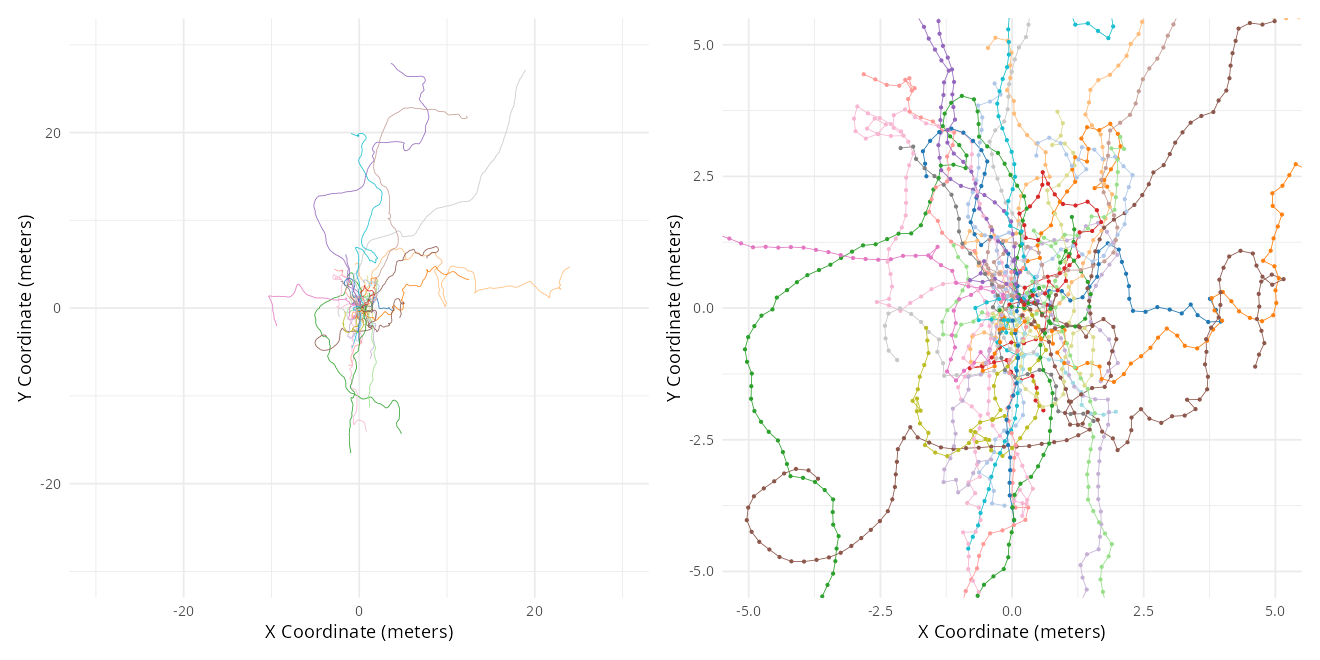

In [11]:
segments <- do.call(rbind, lapply(split(df, df$animal), function(g) {
  g <- g[order(g$iteration), ]
  n <- nrow(g)
  data.frame(animal_id = g$animal_id[-1L], iteration = g$iteration[-1L],
    x = g$X[-n], y = g$Y[-n], xend = g$X[-1L], yend = g$Y[-1L])
}))
tab20 <- c("#1F77B4", "#AEC7E8", "#FF7F0E", "#FFBB78", "#2CA02C", "#98DF8A",
           "#D62728", "#FF9896", "#9467BD", "#C5B0D5", "#8C564B", "#C49C94",
           "#E377C2", "#F7B6D2", "#7F7F7F", "#C7C7C7", "#BCBD22", "#DBDB8D",
           "#17BECF", "#9EDAE5")
trajectory_panel <- function(limit, points = FALSE) {
  p <- ggplot(segments, aes(x, y, colour = factor(animal_id %% 20L))) +
    geom_segment(aes(xend = xend, yend = yend), linewidth = 0.25) +
    scale_colour_manual(values = tab20) +
    coord_equal(xlim = c(-limit, limit), ylim = c(-limit, limit)) +
    labs(x = "X Coordinate (meters)", y = "Y Coordinate (meters)") +
    theme(legend.position = "none")
  if (points) p <- p + geom_point(data = df,
    aes(X, Y, colour = factor(animal_id %% 20L)), inherit.aes = FALSE, size = 0.6)
  p
}
p_trajectories <- trajectory_panel(30) + trajectory_panel(5, points = TRUE)
save_figure(p_trajectories, "locust_directional_trajectories", 12, 6)


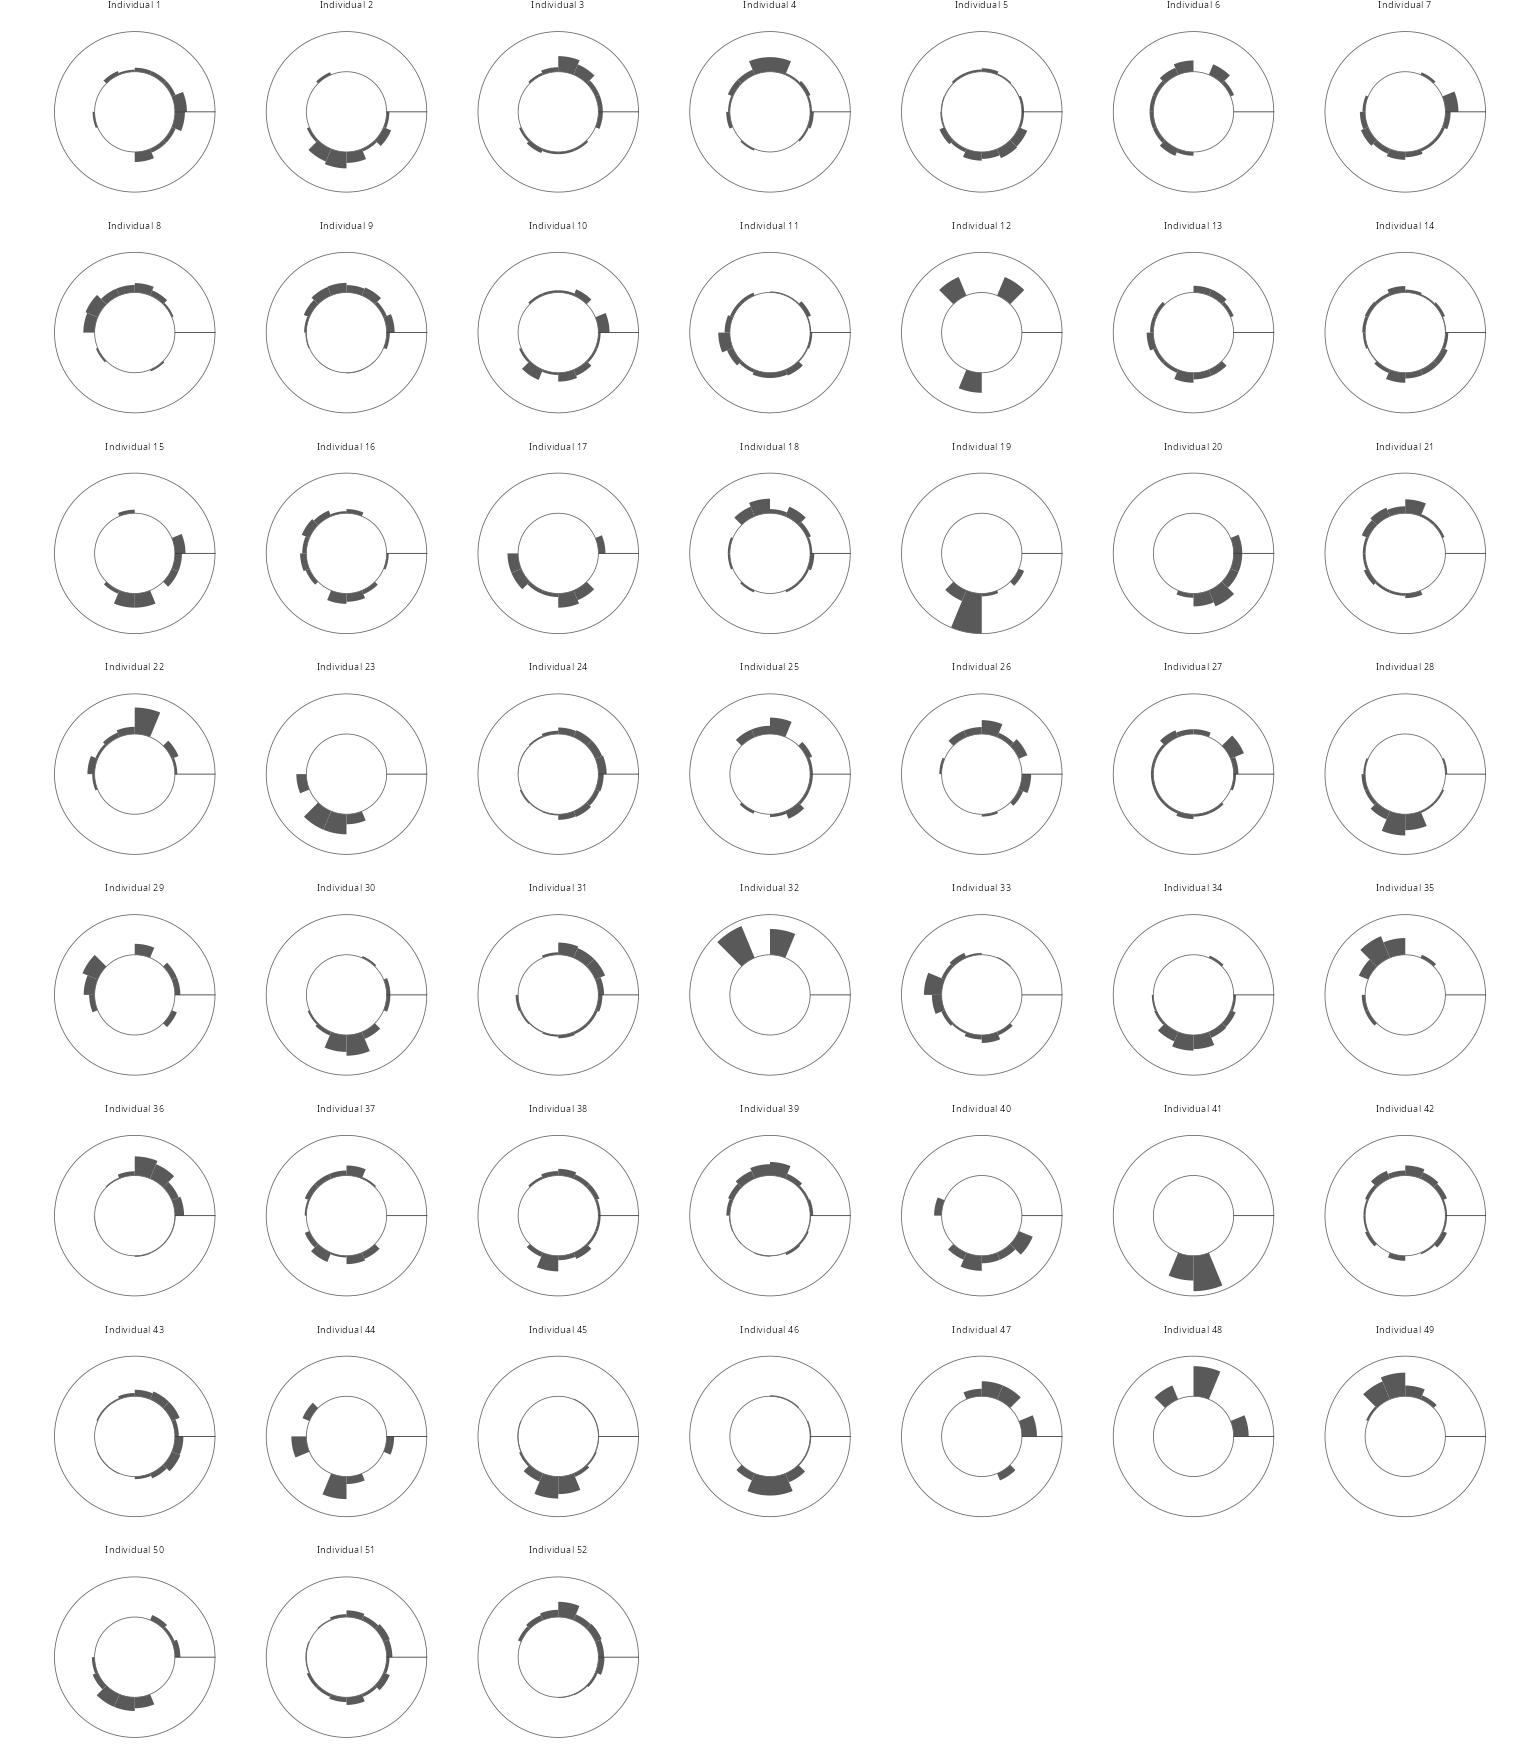

In [12]:
raw_bins <- seq(-pi, pi, length.out = 17L)
raw_densities <- do.call(rbind, lapply(seq_len(num_individuals), function(i) {
  y <- df$direction[df$animal_id == i - 1L]
  bin <- findInterval(wrap(y), raw_bins, rightmost.closed = TRUE)
  data.frame(individual = i, left = head(raw_bins, -1L), right = tail(raw_bins, -1L),
    density = tabulate(bin, nbins = 16L) / (length(y) * diff(raw_bins)))
}))
raw_densities$individual <- factor(raw_densities$individual,
  levels = seq_len(num_individuals), labels = paste("Individual", seq_len(num_individuals)))
# Same radius convention as the other polar figures: density zero sits on
# the ring at radius 1 (the bars rise from it) and the shared peak of all
# 52 histograms sits on the ring at radius 2; the 0-degree spoke marks the
# 3 o'clock zero of the mathematical orientation.
peak_max_hist <- max(raw_densities$density)
raw_densities$radius <- 1 + raw_densities$density / peak_max_hist
p_observed <- ggplot(raw_densities) +
  geom_rect(aes(xmin = left, xmax = right, ymin = 1, ymax = radius), fill = "grey35") +
  geom_hline(yintercept = c(1, 2), colour = "grey40", linewidth = 0.25) +
  geom_segment(data = data.frame(x = 0, xend = 0, y = 1, yend = 2.01),
    inherit.aes = FALSE,
    aes(x = x, xend = xend, y = y, yend = yend),
    colour = "grey20", linewidth = 0.25) +
  scale_x_continuous(limits = c(-pi, pi), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, 2.05), expand = c(0, 0)) +
  coord_polar(start = pi / 2, direction = -1) +
  facet_wrap(~ individual, ncol = 7) + theme_void(base_size = 8)
save_figure(p_observed, "locust_directional_observed_polar_grid", 14, 16)

## Model definition: hierarchical bimodal von Mises mixture

To model the potentially bimodal directional heading patterns of the marching locusts, the analysis uses a hierarchical bimodal von Mises mixture model: population-level (shared) mixture parameters plus individual-specific offsets, with the link functions keeping the parameters in their appropriate domains.

### Individual-level likelihood

For individual $i$, a heading $y \in (-\pi,\pi]$ has likelihood

$$
p(y \mid \Theta_i)
= \omega_i\,\mathcal M\!\bigl(y \mid \mu_{i,1},\kappa_{i,1}\bigr)
+ \bigl(1-\omega_i\bigr)\,\mathcal M\!\bigl(y \mid \mu_{i,2},\kappa_{i,2}\bigr),
$$

where

$$
\mathcal M(y \mid \mu,\kappa)
= \frac{1}{2\pi I_0(\kappa)}\exp\bigl(\kappa\cos(y-\mu)\bigr).
$$

Here:

- $\Theta_i = \{\mu_{i,1},\mu_{i,2},\kappa_{i,1},\kappa_{i,2},\omega_i\}$ are the parameters for individual $i$.
- $\mu_{i,k}$ are the component mean directions, $\mu_{i,k} \in (-\pi,\pi]$.
- $\kappa_{i,k} > 0$ are the component concentrations.
- $\omega_i \in (0,1)$ is the mixture weight for the first component; the second component has weight $1-\omega_i$.
- $I_0(\kappa)$ is the modified Bessel function of the first kind (order zero).

### Observations and dataset structure

- The full dataset is $Y = \{Y_1,\dots,Y_N\}$, where $N$ is the number of individuals.
- Each $Y_i = \{y_{[i,1]},\dots,y_{[i,M_i]}\}$ is the set of headings for individual $i$, with $M_i$ observations.
- Each $y_{[i,j]}$ is a single heading for individual $i$ at index $j$.

Assuming conditional independence given $\Theta_i$, the full-data likelihood factorizes as

$$
p(Y \mid \Theta)
= \prod_{i=1}^{N} \prod_{j=1}^{M_i} p\!\bigl(y_{[i,j]} \mid \Theta_i\bigr).
$$

### Hierarchical structure: population parameters and offsets

We separate population-level structure from individual-level deviations. Let

$$
\boldsymbol{\mu}_0 = (\mu_{0,1},\mu_{0,2}), \qquad
\boldsymbol{\kappa}_0 = (\kappa_{0,1},\kappa_{0,2}), \qquad
\omega_0 \in (0,1)
$$

denote the population-level mixture parameters, and

$$
\boldsymbol{\mu}_i = (\mu_{i,1},\mu_{i,2}), \qquad
\boldsymbol{\kappa}_i = (\kappa_{i,1},\kappa_{i,2}), \qquad
\omega_i
$$

the corresponding parameters for individual $i$.

Individual parameters are defined as population parameters plus unit-specific offsets on appropriate pre-link scales:

$$
\boldsymbol{\mu}_i = \boldsymbol{\mu}_0 + \mathbf{b}_i,
$$

$$
\operatorname{softplus}^{-1}\!\bigl(\boldsymbol{\kappa}_i\bigr)
= \operatorname{softplus}^{-1}\!\bigl(\boldsymbol{\kappa}_0\bigr) + \mathbf{a}_i,
$$

$$
\operatorname{logit}(\omega_i) = \operatorname{logit}(\omega_0) + c_i,
$$

where:

- $\mathbf{b}_i = (b_{[1,i]}, b_{[2,i]})$ are offsets for the component mean directions.
- $\mathbf{a}_i = (a_{[1,i]}, a_{[2,i]})$ are offsets for the component concentrations on the **pre–softplus** scale.
- $c_i$ is a scalar offset for the mixture weight on the **logit** scale.
- $\operatorname{softplus}(x) = \log(1+\exp x)$ and
  $\operatorname{logit}(\omega) = \log\!\bigl(\omega/(1-\omega)\bigr)$.

Componentwise, for $k \in \{1,2\}$,

$$
\mu_{i,k} = \mu_{0,k} + b_{[k,i]},
$$

$$
\operatorname{softplus}^{-1}(\kappa_{i,k})
= \operatorname{softplus}^{-1}(\kappa_{0,k}) + a_{[k,i]},
$$

and

$$
c_i = \operatorname{logit}(\omega_i) - \operatorname{logit}(\omega_0).
$$

Setting all offsets to zero, $\mathbf{b}_i = \mathbf{0}$, $\mathbf{a}_i = \mathbf{0}$, $c_i = 0$, recovers the **population mixture**
$\Theta_0 = \{\boldsymbol{\mu}_0,\boldsymbol{\kappa}_0,\omega_0\}$.


### R implementation and prior correspondence

Stan samples both unsorted population means and derives one component
order from their linear values on the bounded interval. The likelihood
uses that order to select each animal's means, concentrations, and
weights together. The saved first-component index also determines the
order used for population and individual summaries.
The free unsorted parameters retain their permutation symmetry. The
ordered view identifies the labels used in the analysis.

The first component's logit is the animal's unsorted logit or its
negative, according to the population order. Its weight is the sigmoid
of that signed logit. The second weight is the sigmoid of the opposite
logit.

| Quantity | Bimodal prior | Unimodal prior |
| --- | --- | --- |
| Population angle(s) | VM(0, 0.000001), two independent | VM(0, 0.000001) |
| Angular pooling concentration | LogNormal(log(30), 0.1), per component | LogNormal(log(10), 0.1) |
| Animal angular deviation | VM(0, component pooling concentration) | VM(0, pooling concentration) |
| Population pre-softplus concentration | Normal(log(exp(2)-1), 0.5), per component | Normal(log(exp(1.5)-1), 0.5) |
| Concentration deviation scale | HalfNormal(1.5), per component | HalfNormal(1.5) |
| Standardized concentration deviations | Normal(0, 1), independent | Normal(0, 1), independent |
| Population weight logit | Normal(0, 0.5) | — |
| Weight-logit deviation scale | HalfNormal(3) | — |
| Standardized weight-logit deviations | Normal(0, 1), independent | — |

The uniform factors below bound circular coefficient vectors to one period;
they add constants only. Explicit vector log densities provide the exact von
Mises priors. Gaussian group terms are independent and non-centered. All
coefficient priors refer to uncentered intercepts. The generated Stan is
printed with the model definition, where the bounds, dimensions, target
terms, and links can be checked.


In [13]:
locust_mix <- custom_family("locust_mix",
  dpars = c("mu", "mutwo", "kappa", "kappatwo", "eta"),
  links = c("identity", "identity", "softplus", "softplus", "identity"),
  lb = c(NA, NA, 0, 0, NA), vars = "first_component", type = "real")
locust_vm <- custom_family("locust_vm", dpars = c("mu", "kappa"),
  links = c("identity", "softplus"), lb = c(NA, 0), type = "real")
vm_functions <- modulo_circular_fun + stan_unwrap_fun + stanvar(scode = "
  real locust_wrap(real x) {
    return atan2(sin(x), cos(x));
  }
  real locust_vm_lpdf(real y, real mu, real kappa) {
    return unwrap_von_mises_lpdf(y | locust_wrap(mu), kappa);
  }
  real unwrap_von_mises_vect_lpdf(vector y, real mu, real kappa) {
    real lp = 0;
    for (i in 1:num_elements(y)) lp += unwrap_von_mises_lpdf(y[i] | mu, kappa);
    return lp;
  }
", block = "functions")
mix_functions <- stanvar(scode = "
  real locust_mix_lpdf(real y, real mu, real mutwo, real kappa,
                       real kappatwo, real eta, real first_component) {
    array[2] real means = {mu, mutwo};
    array[2] real concentrations = {kappa, kappatwo};
    int first = first_component == 1 ? 1 : 2;
    int second = 3 - first;
    real sorted_eta = first == 1 ? eta : -eta;
    return log_sum_exp(
      log_inv_logit(sorted_eta) +
        unwrap_von_mises_lpdf(y | locust_wrap(means[first]), concentrations[first]),
      log_inv_logit(-sorted_eta) +
        unwrap_von_mises_lpdf(y | locust_wrap(means[second]), concentrations[second]));
  }
", block = "functions")
# A parameter-dependent order belongs in transformed parameters. Stan
# stores the first index as a real; the likelihood reconstructs the two
# integer indices locally. This is Python's argsort for two angles.
mix_order <- stanvar(scode = "
  real first_component = b_popone[1] <= b_poptwo[1] ? 1 : 2;
", block = "tparameters")
mix_hyper <- stanvar(scode = "real<lower=0> kmu_one; real<lower=0> kmu_two;",
                     block = "parameters")
# All animal coefficient vectors have the same level order, 0..51.
mix_form <- bf(direction ~ mu,
  nlf(mu ~ popone + devone),
  nlf(mutwo ~ poptwo + devtwo),
  popone ~ 1, poptwo ~ 1,
  devone ~ 0 + animal, devtwo ~ 0 + animal,
  kappa ~ 0 + Intercept + (1 | animal),
  kappatwo ~ 0 + Intercept + (1 | animal),
  eta ~ 0 + Intercept + (1 | animal),
  family = locust_mix)
mix_priors <- (
  prior("uniform(-pi(), pi())", class = "b", nlpar = "popone",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "poptwo",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "devone",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "devtwo",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  set_prior("target += unwrap_von_mises_lpdf(b_popone[1] | 0, 1e-6)", check = FALSE) +
  set_prior("target += unwrap_von_mises_lpdf(b_poptwo[1] | 0, 1e-6)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_devone | 0, kmu_one)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_devtwo | 0, kmu_two)", check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_one | log(30), 0.1)", check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_two | log(30), 0.1)", check = FALSE) +
  prior("normal(log(exp(2) - 1), 0.5)", class = "b", coef = "Intercept", dpar = "kappa") +
  prior("normal(log(exp(2) - 1), 0.5)", class = "b", coef = "Intercept", dpar = "kappatwo") +
  prior("normal(0, 1.5)", class = "sd", dpar = "kappa") +
  prior("normal(0, 1.5)", class = "sd", dpar = "kappatwo") +
  prior("normal(0, 0.5)", class = "b", coef = "Intercept", dpar = "eta") +
  prior("normal(0, 3)", class = "sd", dpar = "eta")
)

check_angle_design <- function(stan, design, coefficients) {
  parameter_block <- regmatches(stan,
    regexpr("(?m)^parameters\\s*\\{[^}]*\\}", stan, perl = TRUE))
  parameter_block <- gsub("[[:space:]]", "", parameter_block)
  stopifnot(length(parameter_block) == 1L)
  for (name in names(coefficients)) {
    expected <- coefficients[[name]]
    declaration <- paste0("vector<lower=-3\\.14159[0-9]*,upper=3\\.14159[0-9]*>",
      "\\[K_", name, "\\]b_", name, ";")
    stopifnot(grepl(declaration, parameter_block),
      identical(colnames(design[[paste0("X_", name)]]), expected),
      design[[paste0("K_", name)]] == length(expected))
  }
}
mix_stanvars <- vm_functions + mix_functions + mix_hyper + mix_order
mix_stan <- make_stancode(mix_form, data = df, prior = mix_priors, stanvars = mix_stanvars)
mix_design <- make_standata(mix_form, data = df, prior = mix_priors, stanvars = mix_stanvars)
animal_design <- model.matrix(~ 0 + animal, data = df)
check_angle_design(mix_stan, mix_design,
  list(popone = "Intercept", poptwo = "Intercept",
    devone = colnames(animal_design), devtwo = colnames(animal_design)))
stopifnot(isTRUE(all.equal(mix_design$X_devone, animal_design, check.attributes = FALSE)),
          isTRUE(all.equal(mix_design$X_devtwo, animal_design, check.attributes = FALSE)))
compact_mix_stan <- gsub("[[:space:]]", "", mix_stan)
stopifnot(grepl("first_component=b_popone[1]<=b_poptwo[1]?1:2;", compact_mix_stan, fixed = TRUE),
          grepl("target\\+=locust_mix_lpdf\\([^;]+,first_component\\);", compact_mix_stan),
          grepl("unwrap_von_mises_vect_lpdf(b_devone|0,kmu_one)", compact_mix_stan, fixed = TRUE),
          grepl("unwrap_von_mises_vect_lpdf(b_devtwo|0,kmu_two)", compact_mix_stan, fixed = TRUE))
cat(mix_stan)

// generated with brms 2.23.0
functions {
  /* softplus link function inverse to 'log1p_exp'
   * Args:
   *   x: a positive scalar
   * Returns:
   *   a scalar in (-Inf, Inf)
   */
   real log_expm1(real x) {
     return log(expm1(x));
   }
  /* softplus link function inverse to 'log1p_exp' (vectorized)
   * Args:
   *   x: a positive vector
   * Returns:
   *   a vector in (-Inf, Inf)
   */
   vector log_expm1(vector x) {
     return log(expm1(x));
   }

  
  real modulo_circular(real y) {
    return fmod(y + pi(), 2*pi()) - pi();
  }

  
  real unwrap_von_mises_lpdf(real y, real mu, real kappa) {
    return von_mises_lpdf(y | modulo_circular(mu), kappa);
  }
  real unwrap_von_mises_rng(real mu, real kappa) {
    return von_mises_rng( modulo_circular(mu) , kappa);
  }

  
  real locust_wrap(real x) {
    return atan2(sin(x), cos(x));
  }
  real locust_vm_lpdf(real y, real mu, real kappa) {
    return unwrap_von_mises_lpdf(y | locust_wrap(mu), kappa);
  }
  real unwrap_von_mises_vect

### Fit the bimodal model

NUTS on bounded circular vectors can start chains in separate wrap classes.
The population anchors are the circular means of two clusters on the unit
circle. Animal anchors are wrapped deviations from the corresponding
population anchor, or zero if the animal has no steps in that cluster.
Small seeded jitter is added after wrapping. Initialization changes only
the sampler's path, never the posterior.

Full sampling uses four chains of 8,000 iterations with 4,000 warmup
each (16,000 posterior draws in total), with `adapt_delta = 0.97` and
`max_treedepth = 12`. Quick mode (`UNWRAP_R_QUICK=1`) keeps that full
MCMC budget, because at three-quarters of it the unimodal baseline fit's
`mu_pop` R-hat reached 1.0109, over the 1.01 hard gate; it instead
shortens the cheap post-processing, with fewer bootstrap resamples
(150 instead of 1,000), fewer KDE draws (100 instead of
1,000), and fewer predictive replicates (25 instead of 100). The hard
gates apply in either mode.

In [14]:
set.seed(SEED)
initial_clusters <- kmeans(cbind(cos(df$direction), sin(df$direction)),
                           centers = 2L, nstart = 20L)
cluster_means <- vapply(split(df$direction, initial_clusters$cluster), circ_mean, numeric(1))
cluster_order <- order(cluster_means)
anchor_mix <- as.numeric(mod_circular(cluster_means[cluster_order]))
initial_group <- match(initial_clusters$cluster, cluster_order)
animal_offsets <- function(component) {
  vapply(levels(df$animal), function(id) {
    y <- df$direction[df$animal == id & initial_group == component]
    if (!length(y)) 0 else mod_circular(circ_mean(y) - anchor_mix[component])
  }, numeric(1))
}
anchor_offsets_one <- animal_offsets(1L)
anchor_offsets_two <- animal_offsets(2L)
stopifnot(length(anchor_mix) == mix_design$K_popone + mix_design$K_poptwo,
          length(anchor_offsets_one) == mix_design$K_devone,
          length(anchor_offsets_two) == mix_design$K_devtwo,
          all(abs(anchor_mix) < pi - 0.2),
          all(abs(c(anchor_offsets_one, anchor_offsets_two)) < pi - 0.5))
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.08, 0.08)
  list(b_popone = as.numeric(anchor_mix[1] + j(mix_design$K_popone)),
       b_poptwo = as.numeric(anchor_mix[2] + j(mix_design$K_poptwo)),
       b_devone = as.numeric(anchor_offsets_one + j(mix_design$K_devone)),
       b_devtwo = as.numeric(anchor_offsets_two + j(mix_design$K_devtwo)))
}
init_mix <- lapply(seq_len(CHAINS), function(k) mk_init(SEED + k))
set.seed(SEED)
fit_bimodal <- unwrap_load_fit_cache("locust_mix_bimodal", SEED, ITER, WARMUP)
if (is.null(fit_bimodal)) {
  fit_bimodal <- brm(mix_form, data = df, prior = mix_priors, stanvars = mix_stanvars,
    backend = "cmdstanr", chains = CHAINS, iter = ITER, warmup = WARMUP,
    cores = CHAINS, seed = SEED, init = init_mix,
    control = list(adapt_delta = 0.97, max_treedepth = 12))
  unwrap_save_fit_cache("locust_mix_bimodal", fit_bimodal, SEED, ITER, WARMUP)
}

Loading required namespace: rstan



Unwrap fit cache: reusing 'locust_mix_bimodal' (seed 42, iter 8000, warmup 4000).



In [15]:
animal_grid <- data.frame(animal = factor(levels(df$animal), levels = levels(df$animal)))
extract_state <- function(fit, bimodal = TRUE) {
  draws <- posterior::as_draws_array(fit)
  draw_index <- expand.grid(.iteration = seq_len(dim(draws)[1]),
    .chain = seq_len(dim(draws)[2]), KEEP.OUT.ATTRS = FALSE)
  get <- function(name) {
    stopifnot(name %in% posterior::variables(draws))
    as.numeric(draws[, , name])
  }
  predict_matrix <- function(dpar, transform = FALSE) {
    x <- t(posterior_linpred(fit, newdata = animal_grid,
                            dpar = dpar, transform = transform))
    stopifnot(identical(dim(x), c(num_individuals, nrow(draw_index))))
    x
  }
  m1 <- wrap(predict_matrix("mu"))
  k1 <- predict_matrix("kappa", transform = TRUE)
  p1 <- get("b_popone_Intercept")
  kp1 <- softplus(get("b_kappa_Intercept"))
  if (!bimodal) {
    return(list(draws = draw_index, muone = m1, kone = k1,
      pop_muone = matrix(wrap(p1), nrow = 1L),
      pop_kone = matrix(kp1, nrow = 1L),
      quantities = c(list(mu_pop = wrap(p1), mu_kappa = get("kmu_one"),
        kappa_log_pop = get("b_kappa_Intercept"), kappa_pop = kp1,
        kappa_sigma = get("sd_animal__kappa_Intercept")),
        setNames(lapply(seq_len(num_individuals), function(i) m1[i, ]),
                 paste0("mu[", seq_len(num_individuals), "]")),
        setNames(lapply(seq_len(num_individuals), function(i) k1[i, ]),
                 paste0("kappa[", seq_len(num_individuals), "]")))))
  }
  m2 <- wrap(predict_matrix("mutwo"))
  k2 <- predict_matrix("kappatwo", transform = TRUE)
  eta <- predict_matrix("eta")
  p2 <- get("b_poptwo_Intercept")
  kp2 <- softplus(get("b_kappatwo_Intercept"))
  eta_pop <- get("b_eta_Intercept")
  first_component <- get("first_component")
  stopifnot(all(first_component %in% 1:2),
            all((first_component == 2) == (p1 > p2)))
  swap <- first_component == 2
  # Read the saved Stan index for all summaries and predictive draws.
  reorder_pair <- function(a, b) {
    stopifnot(identical(dim(a), dim(b)), ncol(a) == length(swap))
    first <- a
    second <- b
    first[, swap] <- b[, swap, drop = FALSE]
    second[, swap] <- a[, swap, drop = FALSE]
    list(first, second)
  }
  means <- reorder_pair(m1, m2)
  kappas <- reorder_pair(k1, k2)
  pop_means <- reorder_pair(matrix(p1, nrow = 1L), matrix(p2, nrow = 1L))
  pop_kappas <- reorder_pair(matrix(kp1, nrow = 1L), matrix(kp2, nrow = 1L))
  pool_k <- reorder_pair(matrix(get("kmu_one"), nrow = 1L),
                         matrix(get("kmu_two"), nrow = 1L))
  sigma_k <- reorder_pair(matrix(get("sd_animal__kappa_Intercept"), nrow = 1L),
                          matrix(get("sd_animal__kappatwo_Intercept"), nrow = 1L))
  eta[, swap] <- -eta[, swap, drop = FALSE]
  eta_pop[swap] <- -eta_pop[swap]
  w <- plogis(eta)
  wp <- plogis(eta_pop)
  quantities <- list(logit_sigma = get("sd_animal__eta_Intercept"),
                     weights_pop = wp)
  for (k in 1:2) {
    quantities[[paste0("mu_pop[", k, "]")]] <- as.numeric(pop_means[[k]])
    quantities[[paste0("mu_kappa[", k, "]")]] <- as.numeric(pool_k[[k]])
    quantities[[paste0("kappa_pop[", k, "]")]] <- as.numeric(pop_kappas[[k]])
    quantities[[paste0("kappa_sigma[", k, "]")]] <- as.numeric(sigma_k[[k]])
    for (i in seq_len(num_individuals)) {
      quantities[[paste0("mu[", i, ",", k, "]")]] <- means[[k]][i, ]
      quantities[[paste0("kappa[", i, ",", k, "]")]] <- kappas[[k]][i, ]
    }
  }
  for (i in seq_len(num_individuals)) quantities[[paste0("weights[", i, "]")]] <- w[i, ]
  list(draws = draw_index, muone = means[[1]], mutwo = means[[2]],
       kone = kappas[[1]], ktwo = kappas[[2]], weight = w, eta = eta,
       pop_muone = pop_means[[1]], pop_mutwo = pop_means[[2]],
       pop_kone = pop_kappas[[1]], pop_ktwo = pop_kappas[[2]],
       pop_weight = matrix(wp, nrow = 1L), pop_eta = matrix(eta_pop, nrow = 1L),
       quantities = quantities)
}
chain_matrix <- function(x, draws) {
  stopifnot(length(x) == nrow(draws))
  ids <- split(seq_len(nrow(draws)), draws[[".chain"]])
  stopifnot(length(ids) >= 2L, length(unique(lengths(ids))) == 1L)
  do.call(cbind, lapply(ids, function(ii) x[ii[order(draws[[".iteration"]][ii])]]))
}
diagnose_fit <- function(fit, state) {
  # Same retained-flag probe as the P1 helpers; absence is not zero.
  divergences <- tryCatch({
    samples <- fit$fit@sim$samples
    if (is.null(samples) || !length(samples)) {
      NA_real_
    } else {
      flags <- lapply(samples, function(ch) ch[["divergent"]])
      if (any(vapply(flags, is.null, logical(1)))) NA_real_ else sum(unlist(flags))
    }
  }, error = function(e) NA_real_)
  if (is.na(divergences)) {
    cat("Divergences: not retained in this fit object.\n")
  } else {
    cat("Divergences:", divergences, "\n")
  }
  table <- do.call(rbind, lapply(names(state$quantities), function(p) {
    x <- chain_matrix(state$quantities[[p]], state$draws)
    stopifnot(all(is.finite(x)))
    angular <- grepl("^mu(\\[|_pop($|\\[))", p)
    z <- if (angular) wrap(x - circ_mean(x)) else x
    data.frame(parameter = p,
      mean = if (angular) circ_mean(x) else mean(x),
      sd = if (angular) sqrt(-2 * log(min(1, resultant(x)))) else sd(as.numeric(x)),
      rhat = if (angular) Rhat_unwrap(x, method = "sine") else posterior::rhat(x),
      ess_bulk = posterior::ess_bulk(z), row.names = NULL)
  }))
  # Angular R-hat uses the Rhat_unwrap sine/cosine convention. Every ESS
  # and R-hat calculation receives an [iteration x chain] matrix.
  failed <- table[!is.finite(table$rhat) | table$rhat >= 1.01 |
    !is.finite(table$ess_bulk) | table$ess_bulk <= 400, , drop = FALSE]
  print(failed, row.names = FALSE)
  stopifnot(nrow(failed) == 0L, is.na(divergences) || divergences == 0)
  table
}
trace_plot <- function(state, parameters) {
  long <- do.call(rbind, lapply(parameters, function(p) {
    x <- state$quantities[[p]]
    stopifnot(!is.null(x))
    if (grepl("^mu(\\[|_pop($|\\[))", p)) x <- wrap(x - circ_mean(x))
    data.frame(parameter = p, iteration = state$draws[[".iteration"]],
               chain = factor(state$draws[[".chain"]]), value = x)
  }))
  ggplot(long, aes(iteration, value, colour = chain, group = chain)) +
    geom_line(linewidth = 0.25, alpha = 0.65) +
    facet_wrap(~ parameter, scales = "free_y", ncol = 2) +
    labs(x = "retained iteration", y = "draw (angular traces centered)") +
    theme(legend.position = "bottom")
}
state_bimodal <- extract_state(fit_bimodal)
summary_bimodal <- diagnose_fit(fit_bimodal, state_bimodal)

Divergences: not retained in this fit object.
[1] parameter mean      sd        rhat      ess_bulk 
<0 rows> (or 0-length row.names)


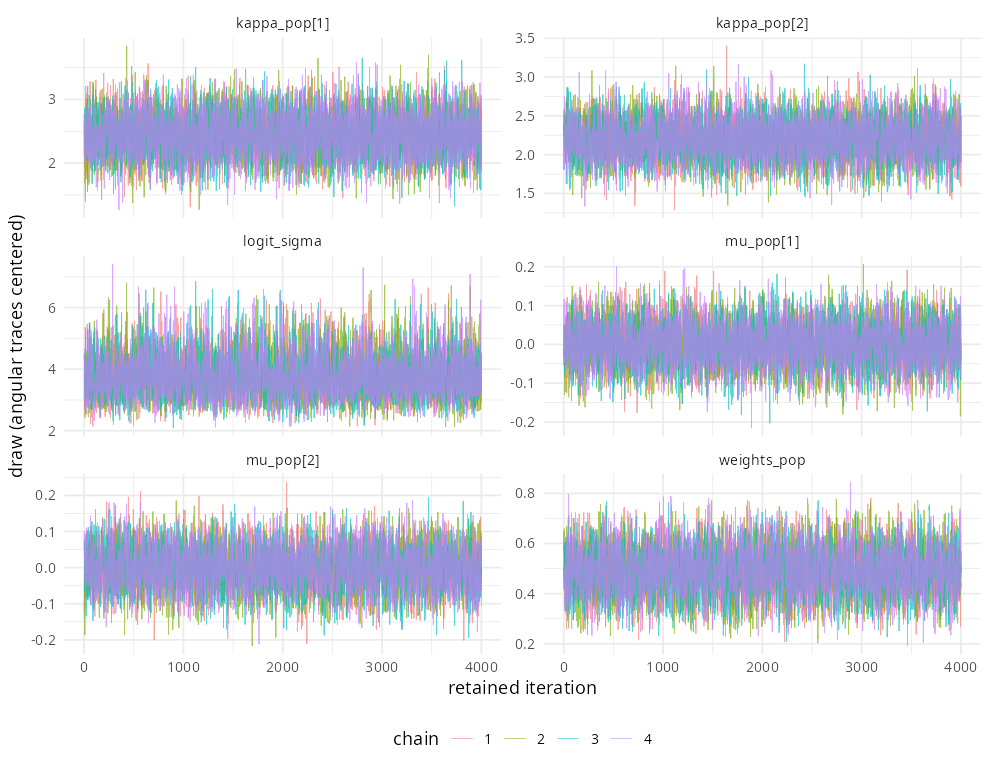

In [16]:
save_figure(trace_plot(state_bimodal,
  c("mu_pop[1]", "mu_pop[2]", "kappa_pop[1]", "kappa_pop[2]", "weights_pop", "logit_sigma")),
  "bimodal_trace", 9, 7)


## Hierarchical unimodal von Mises model

For comparison to the bimodal mixture, we also fit a hierarchical **unimodal** von Mises model in which each individual has a single preferred direction and concentration.

For individual $i$, a heading $y \in (-\pi,\pi]$ has likelihood

$$
p(y \mid \Theta_i)
= \mathcal M(y \mid \mu_i,\kappa_i),
$$

with

$$
\mathcal M(y \mid \mu,\kappa)
= \frac{1}{2\pi I_0(\kappa)} \exp\bigl(\kappa \cos(y-\mu)\bigr),
$$

where $\Theta_i = \{\mu_i,\kappa_i\}$, the mean direction $\mu_i \in (-\pi,\pi]$, the concentration $\kappa_i > 0$, and $I_0(\kappa)$ is the modified Bessel function of the first kind of order zero.

Let $Y_i = \{y_{[i,1]},\dots,y_{[i,M_i]}\}$ denote the headings for individual $i$, and $Y = \{Y_1,\dots,Y_N\}$ the full dataset from $N$ individuals.
As in the bimodal case, we separate population-level structure from individual-level deviations via a hierarchical parameterization.

This unimodal hierarchical model provides a simpler baseline in which each animal has a single preferred direction $\mu_i$ and concentration $\kappa_i$, regularized toward shared population values $(\mu_0,\kappa_0)$. It is used as a comparison point for the more flexible bimodal mixture model to assess whether the data warrant modeling two distinct directional modes.


In [17]:
uni_hyper <- stanvar(scode = "real<lower=0> kmu_one;", block = "parameters")
uni_form <- bf(direction ~ mu,
  nlf(mu ~ popone + devone),
  popone ~ 1, devone ~ 0 + animal,
  kappa ~ 0 + Intercept + (1 | animal), family = locust_vm)
uni_priors <- (
  prior("uniform(-pi(), pi())", class = "b", nlpar = "popone",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  prior("uniform(-pi(), pi())", class = "b", nlpar = "devone",
    lb = -3.141592653589793, ub = 3.141592653589793) +
  set_prior("target += unwrap_von_mises_lpdf(b_popone[1] | 0, 1e-6)", check = FALSE) +
  set_prior("target += unwrap_von_mises_vect_lpdf(b_devone | 0, kmu_one)", check = FALSE) +
  set_prior("target += lognormal_lpdf(kmu_one | log(10), 0.1)", check = FALSE) +
  prior("normal(log(exp(1.5) - 1), 0.5)", class = "b", coef = "Intercept", dpar = "kappa") +
  prior("normal(0, 1.5)", class = "sd", dpar = "kappa")
)
uni_stanvars <- vm_functions + uni_hyper
uni_stan <- make_stancode(uni_form, data = df, prior = uni_priors, stanvars = uni_stanvars)

uni_design <- make_standata(uni_form, data = df, prior = uni_priors, stanvars = uni_stanvars)
check_angle_design(uni_stan, uni_design,
  list(popone = "Intercept", devone = colnames(animal_design)))
stopifnot(isTRUE(all.equal(uni_design$X_devone, animal_design, check.attributes = FALSE)))
compact_uni_stan <- gsub("[[:space:]]", "", uni_stan)
stopifnot(grepl("target+=locust_vm_lpdf", compact_uni_stan, fixed = TRUE),
          grepl("unwrap_von_mises_vect_lpdf(b_devone|0,kmu_one)", compact_uni_stan, fixed = TRUE),
          grepl("lognormal_lpdf(kmu_one|log(10),0.1)", compact_uni_stan, fixed = TRUE))
cat(uni_stan)

// generated with brms 2.23.0
functions {
  /* softplus link function inverse to 'log1p_exp'
   * Args:
   *   x: a positive scalar
   * Returns:
   *   a scalar in (-Inf, Inf)
   */
   real log_expm1(real x) {
     return log(expm1(x));
   }
  /* softplus link function inverse to 'log1p_exp' (vectorized)
   * Args:
   *   x: a positive vector
   * Returns:
   *   a vector in (-Inf, Inf)
   */
   vector log_expm1(vector x) {
     return log(expm1(x));
   }
  
  real modulo_circular(real y) {
    return fmod(y + pi(), 2*pi()) - pi();
  }

  
  real unwrap_von_mises_lpdf(real y, real mu, real kappa) {
    return von_mises_lpdf(y | modulo_circular(mu), kappa);
  }
  real unwrap_von_mises_rng(real mu, real kappa) {
    return von_mises_rng( modulo_circular(mu) , kappa);
  }

  
  real locust_wrap(real x) {
    return atan2(sin(x), cos(x));
  }
  real locust_vm_lpdf(real y, real mu, real kappa) {
    return unwrap_von_mises_lpdf(y | locust_wrap(mu), kappa);
  }
  real unwrap_von_mises_vect_

The unimodal fit starts from the pooled circular mean if it leaves room
for each animal's wrapped deviation. If an animal's mean is too close
to the deviation seam, the seam is placed midway through the largest gap
between the animal means, and the population angle is anchored opposite it.
Independent seeded jitter is added after wrapping.

In [18]:
data_anchor <- as.numeric(mod_circular(circ_mean(df$direction)))
individual_anchor <- vapply(split(df$direction, df$animal), circ_mean, numeric(1))
anchor_offsets <- as.numeric(mod_circular(individual_anchor - data_anchor))
if (abs(data_anchor) >= pi - 0.2 || any(abs(anchor_offsets) >= pi - 0.5)) {
  ordered_means <- sort(individual_anchor)
  gaps <- diff(c(ordered_means, ordered_means[1] + 2 * pi))
  widest <- which.max(gaps)
  seam <- ordered_means[widest] + gaps[widest] / 2
  data_anchor <- as.numeric(mod_circular(seam + pi))
  anchor_offsets <- as.numeric(mod_circular(individual_anchor - data_anchor))
}
stopifnot(length(data_anchor) == uni_design$K_popone,
          length(anchor_offsets) == uni_design$K_devone,
          abs(data_anchor) < pi - 0.2, all(abs(anchor_offsets) < pi - 0.5))
mk_init <- function(anchor_seed) {
  set.seed(anchor_seed)
  j <- function(n) runif(n, -0.08, 0.08)
  list(b_popone = as.numeric(data_anchor + j(uni_design$K_popone)),
       b_devone = as.numeric(anchor_offsets + j(uni_design$K_devone)))
}
init_uni <- lapply(seq_len(CHAINS), function(k) mk_init(SEED + k))
set.seed(SEED)
fit_unimodal <- unwrap_load_fit_cache("locust_mix_unimodal", SEED, ITER, WARMUP)
if (is.null(fit_unimodal)) {
  fit_unimodal <- brm(uni_form, data = df, prior = uni_priors, stanvars = uni_stanvars,
    backend = "cmdstanr", chains = CHAINS, iter = ITER, warmup = WARMUP,
    cores = CHAINS, seed = SEED, init = init_uni,
    control = list(adapt_delta = 0.97, max_treedepth = 12))
  unwrap_save_fit_cache("locust_mix_unimodal", fit_unimodal, SEED, ITER, WARMUP)
}
state_unimodal <- extract_state(fit_unimodal, bimodal = FALSE)
summary_unimodal <- diagnose_fit(fit_unimodal, state_unimodal)

Unwrap fit cache: reusing 'locust_mix_unimodal' (seed 42, iter 8000, warmup 4000).



Divergences: not retained in this fit object.
[1] parameter mean      sd        rhat      ess_bulk 
<0 rows> (or 0-length row.names)


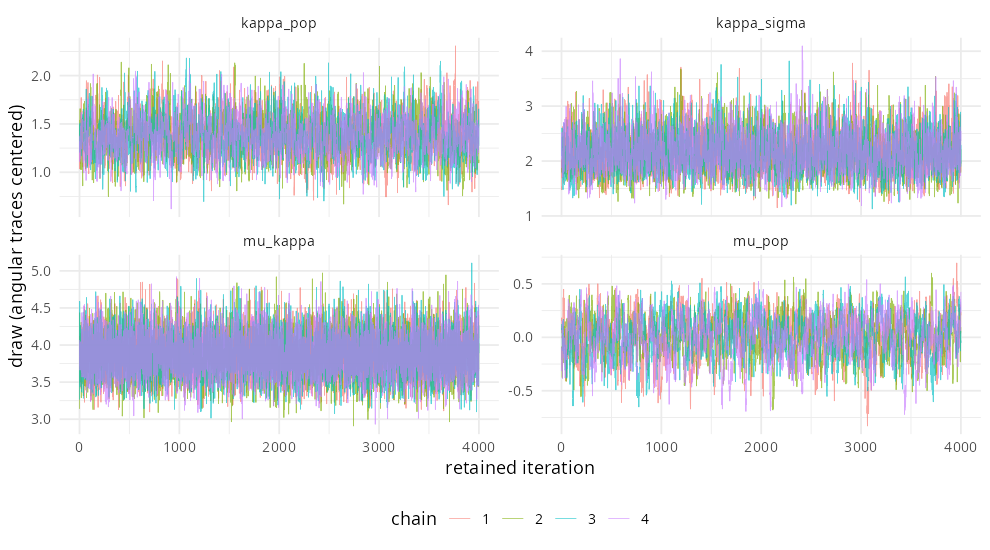

In [19]:
save_figure(trace_plot(state_unimodal,
  c("mu_pop", "mu_kappa", "kappa_pop", "kappa_sigma")), "unimodal_trace", 9, 5)


## Model comparison: bimodal vs. unimodal

PSIS-LOO targets a held-out **step conditional on the observed animals**,
and the pointwise log likelihood is the value each step contributes, so the
comparison is at step level, not leave-one-animal-out validation. The log
likelihoods are evaluated explicitly from the fitted mixture parameters,
with every posterior draw and its chain retained. The Pareto-k diagnostics
printed with each fit should be reviewed before the comparison is interpreted.

The per-animal panels show the mean pointwise log predictive density of each
animal without interval bars — a single value per animal carries no standard
error. The total model ELPDs use the PSIS-LOO standard errors; the total
paired-difference table additionally reports
$\sqrt{N\,\operatorname{var}(\Delta_{\text{pointwise}})}$, the
scale of the 2,435 per-step ELPD differences.



Computed from 16000 by 2435 log-likelihood matrix.

         Estimate   SE
elpd_loo  -3404.5 39.2
p_loo       119.5  3.7
looic      6809.0 78.5
------
MCSE of elpd_loo is NA.
MCSE and ESS estimates assume MCMC draws (r_eff in [0.2, 2.4]).

Pareto k diagnostic values:
                         Count Pct.    Min. ESS
(-Inf, 0.7]   (good)     2434  100.0%  3039    
   (0.7, 1]   (bad)         1    0.0%  <NA>    
   (1, Inf)   (very bad)    0    0.0%  <NA>    
See help('pareto-k-diagnostic') for details.
Pareto k diagnostic values:
                         Count Pct.    Min. ESS
(-Inf, 0.7]   (good)     2434  100.0%  3039    
   (0.7, 1]   (bad)         1    0.0%  <NA>    
   (1, Inf)   (very bad)    0    0.0%  <NA>    



Computed from 16000 by 2435 log-likelihood matrix.

         Estimate   SE
elpd_loo  -3501.2 38.8
p_loo        92.3  3.6
looic      7002.5 77.5
------
MCSE of elpd_loo is NA.
MCSE and ESS estimates assume MCMC draws (r_eff in [0.1, 2.0]).

Pareto k diagnostic values:
                         Count Pct.    Min. ESS
(-Inf, 0.7]   (good)     2428  99.7%   1032    
   (0.7, 1]   (bad)         5   0.2%   <NA>    
   (1, Inf)   (very bad)    2   0.1%   <NA>    
See help('pareto-k-diagnostic') for details.
Pareto k diagnostic values:
                         Count Pct.    Min. ESS
(-Inf, 0.7]   (good)     2428  99.7%   1032    
   (0.7, 1]   (bad)         5   0.2%   <NA>    
   (1, Inf)   (very bad)    2   0.1%   <NA>    


     model      elpd       se max_pareto_k n_pareto_k_gt_0.7
1  Bimodal -3404.488 39.24214    0.7041202                 1
2 Unimodal -3501.249 38.76290    1.4213408                 7


          comparison delta_elpd       se
1 Bimodal - Unimodal   96.76108 16.71045


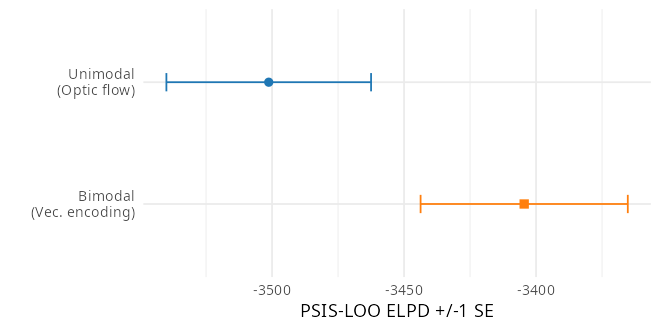

In [20]:
explicit_loo <- function(state, bimodal = TRUE, chunk_size = 128L) {
  S <- nrow(state$draws)
  ll <- matrix(NA_real_, nrow = S, ncol = nrow(df))
  for (start in seq.int(1L, nrow(df), by = chunk_size)) {
    ii <- seq.int(start, min(start + chunk_size - 1L, nrow(df)))
    a <- df$animal_id[ii] + 1L
    y <- matrix(rep(df$direction[ii], S), nrow = length(ii))
    l1 <- vm_logpdf(y, state$muone[a, , drop = FALSE], state$kone[a, , drop = FALSE])
    if (bimodal) {
      eta <- state$eta[a, , drop = FALSE]
      l2 <- vm_logpdf(y, state$mutwo[a, , drop = FALSE], state$ktwo[a, , drop = FALSE])
      ll[, ii] <- t(log_add(-softplus(-eta) + l1, -softplus(eta) + l2))
    } else {
      ll[, ii] <- t(l1)
    }
  }
  stopifnot(all(is.finite(ll)))
  # Scale each likelihood column before exponentiating; relative_eff is
  # invariant to this scaling. Preserve chain IDs rather than flattening.
  likelihood <- exp(sweep(ll, 2, apply(ll, 2, max), "-"))
  r_eff <- loo::relative_eff(likelihood, chain_id = state$draws[[".chain"]])
  # The full Pareto-k table is printed below and its summary columns are
  # carried in the ELPD table, so suppress loo()'s redundant high-k nag.
  result <- suppressWarnings(loo::loo(ll, r_eff = r_eff))
  print(result)
  print(loo::pareto_k_table(result))
  result
}
loo_bimodal <- explicit_loo(state_bimodal)
loo_unimodal <- explicit_loo(state_unimodal, bimodal = FALSE)
models <- list(Bimodal = loo_bimodal, Unimodal = loo_unimodal)
elpd_table <- do.call(rbind, lapply(names(models), function(name) {
  x <- models[[name]]
  data.frame(model = name, elpd = x$estimates["elpd_loo", "Estimate"],
    se = x$estimates["elpd_loo", "SE"], max_pareto_k = max(x$diagnostics$pareto_k),
    n_pareto_k_gt_0.7 = sum(x$diagnostics$pareto_k > 0.7))
}))
delta_pointwise <- loo_bimodal$pointwise[, "elpd_loo"] - loo_unimodal$pointwise[, "elpd_loo"]
print(elpd_table)
print(data.frame(comparison = "Bimodal - Unimodal", delta_elpd = sum(delta_pointwise),
                 se = sqrt(length(delta_pointwise) * var(delta_pointwise))))
model_labels <- c(Bimodal = "Bimodal\n(Vec. encoding)",
                  Unimodal = "Unimodal\n(Optic flow)")
p_elpd <- ggplot(elpd_table, aes(elpd, factor(model, levels = c("Bimodal", "Unimodal")),
                                 colour = model, shape = model)) +
  scale_y_discrete(labels = model_labels) +
  geom_errorbar(aes(xmin = elpd - se, xmax = elpd + se), orientation = "y", width = 0.15) +
  geom_point(size = 2.5) + scale_colour_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_shape_manual(values = c(Bimodal = 15, Unimodal = 16)) +
  labs(x = "PSIS-LOO ELPD +/-1 SE", y = "") + theme(legend.position = "none")
save_figure(p_elpd, "locust_bimodal_unimodal_elpd", 6, 3)

   individual     bimodal    unimodal        delta se
1           1  -52.290633  -48.239118 -4.051515272  0
2           2  -29.200144  -29.636264  0.436119763  0
3           3  -42.504613  -46.484657  3.980043784  0
4           4  -48.268254  -48.515547  0.247293092  0
5           5 -221.750157 -227.425627  5.675470136  0
6           6  -28.978190  -30.228898  1.250707561  0
7           7  -40.658411  -41.288575  0.630164380  0
8           8  -44.382584  -43.615377 -0.767206674  0
9           9 -265.642243 -265.376966 -0.265276848  0
10         10  -47.947087  -48.261641  0.314553703  0
11         11 -101.885222 -101.154228 -0.730994131  0
12         12   -5.912389   -6.393047  0.480658412  0
13         13  -33.714467  -33.784872  0.070405560  0
14         14 -147.389958 -154.148429  6.758471145  0
15         15  -25.712210  -25.346273 -0.365937019  0
16         16  -53.175990  -54.021250  0.845259105  0
17         17  -25.864033  -26.668937  0.804903611  0
18         18  -45.749676  -

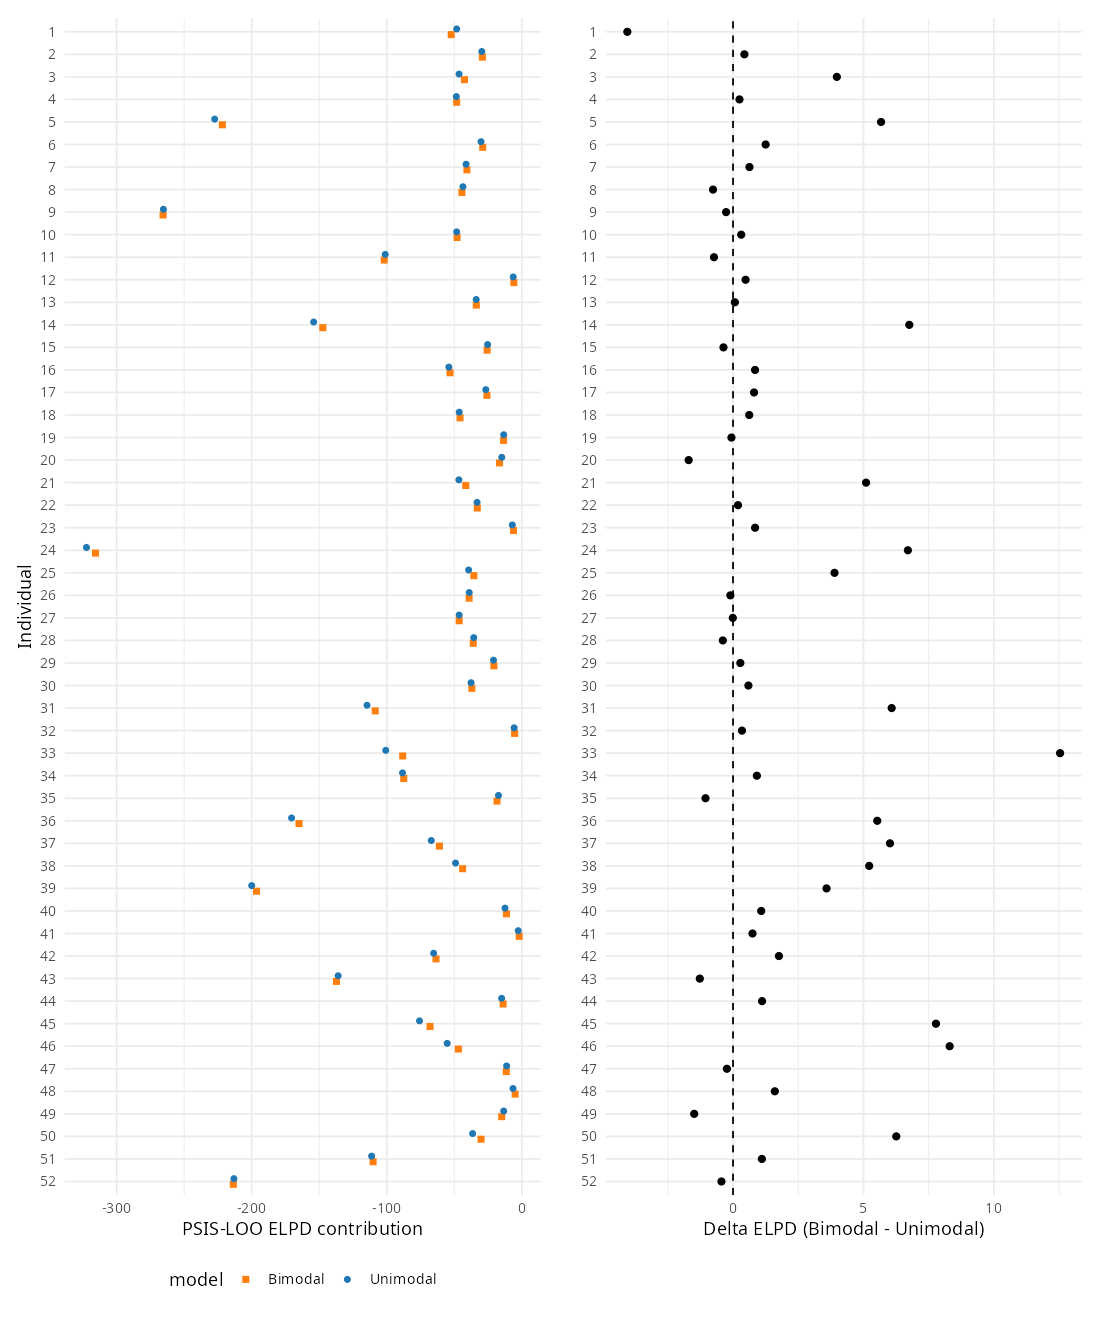

In [21]:
elpd_individual <- do.call(rbind, lapply(seq_len(num_individuals), function(i) {
  ii <- which(df$animal_id == i - 1L)
  data.frame(individual = i,
    bimodal = sum(loo_bimodal$pointwise[ii, "elpd_loo"]),
    unimodal = sum(loo_unimodal$pointwise[ii, "elpd_loo"]),
    delta = sum(delta_pointwise[ii]), se = 0)
}))
print(elpd_individual)
individual_levels <- rev(as.character(seq_len(num_individuals)))
elpd_long <- rbind(data.frame(individual = elpd_individual$individual,
                             value = elpd_individual$bimodal, model = "Bimodal"),
                   data.frame(individual = elpd_individual$individual,
                             value = elpd_individual$unimodal, model = "Unimodal"))
p_elpd_individual <- ggplot(elpd_long,
  aes(value, factor(individual, levels = individual_levels), colour = model, shape = model)) +
  geom_point(position = position_dodge(width = 0.5), size = 1.8) +
  scale_colour_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_shape_manual(values = c(Bimodal = 15, Unimodal = 16)) +
  labs(x = "PSIS-LOO ELPD contribution", y = "Individual") + theme(legend.position = "bottom")
p_delta <- ggplot(elpd_individual,
  aes(delta, factor(individual, levels = individual_levels))) +
  geom_point(size = 1.8) + geom_vline(xintercept = 0, linetype = "dashed") +
  labs(x = "Delta ELPD (Bimodal - Unimodal)", y = "")
save_figure(p_elpd_individual + p_delta,
  "locust_elpd_by_individual_ab", 10, 12)


## Posterior predictive check: model density vs. non-parametric estimates

The population-level check compares the **posterior predictive density** of the fitted hierarchical model with two **non-parametric estimates** of the population-level directional density:
a hierarchical-bootstrap circular histogram (animals resampled with replacement)
and a von Mises kernel density estimate (KDE) with a bootstrap interval.
Together they show how well the fitted model reproduces the dominant
population-level directional pattern.


The validation plots use the bimodal population parameters with the animal
offsets set to zero. The observed-sample density bootstraps animals with
replacement, resamples steps within each selected animal, then averages the
animal densities with equal weight. The histogram uses 16 bins on a
360-point grid; the von Mises KDE has kernel concentration 30 for the
population and 15 for individuals. The bootstrap is redrawn in this
notebook, so its random realization differs from run to run.

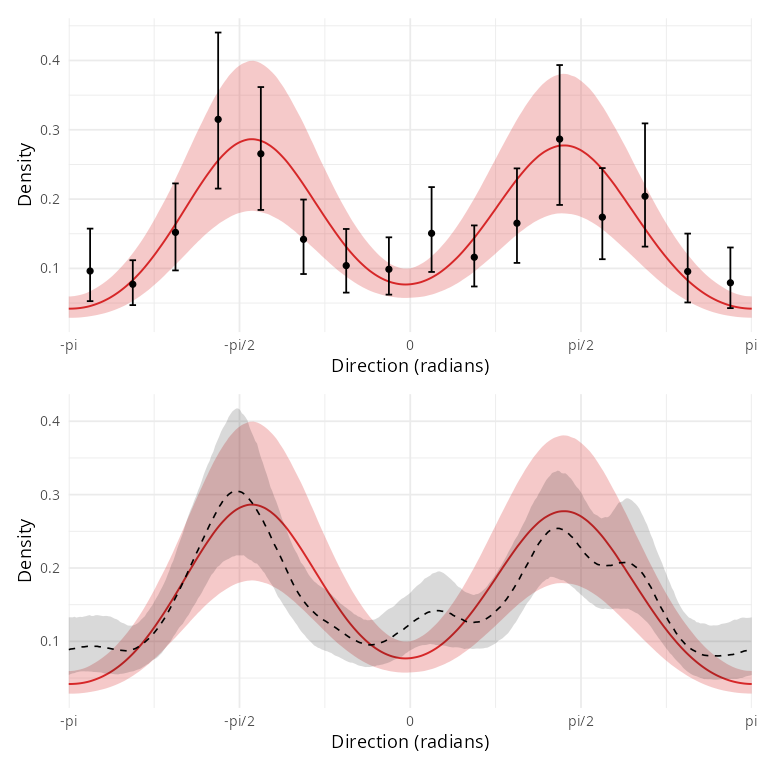

In [22]:
population_state <- list(muone = state_bimodal$pop_muone,
  mutwo = state_bimodal$pop_mutwo, kone = state_bimodal$pop_kone,
  ktwo = state_bimodal$pop_ktwo, weight = state_bimodal$pop_weight,
  eta = state_bimodal$pop_eta)
theta_grid <- seq(-pi, pi, length.out = 360L)
pop_mu <- rbind(as.numeric(population_state$muone), as.numeric(population_state$mutwo))
pop_kappa <- rbind(as.numeric(population_state$kone), as.numeric(population_state$ktwo))
pop_pdf <- mixture_grid(theta_grid, pop_mu, pop_kappa, as.numeric(population_state$weight))
stopifnot(identical(dim(pop_pdf), c(length(theta_grid), nrow(state_bimodal$draws))))
# Python population_density summarizes log density first, then exponentiates.
q_pop <- exp(t(apply(log(pop_pdf), 1, quantile, probs = c(0.025, 0.5, 0.975))))
model_density <- data.frame(theta = theta_grid,
  low = q_pop[, 1], center = q_pop[, 2], high = q_pop[, 3])
rm(pop_pdf)
rows_by_animal <- split(seq_len(nrow(df)), df$animal)
bins <- seq(-pi, pi, length.out = 17L)
bin_width <- diff(bins)[1]
bin_id <- findInterval(wrap(df$direction), bins, rightmost.closed = TRUE)
stopifnot(all(bin_id >= 1L & bin_id <= 16L))
hist_kernel <- matrix(0, nrow = 16L, ncol = nrow(df))
hist_kernel[cbind(bin_id, seq_len(nrow(df)))] <- 1 / bin_width
# Each column is one observed heading's VM kernel on the theta grid.
kde_kernel <- kde_basis(theta_grid, df$direction, bw = 30)
boot_hist <- matrix(0, nrow = 16L, ncol = N_BOOTSTRAPS)
boot_kde <- matrix(0, nrow = length(theta_grid), ncol = N_BOOTSTRAPS)
set.seed(123)
for (b in seq_len(N_BOOTSTRAPS)) {
  selected <- sample.int(num_individuals, num_individuals, replace = TRUE)
  weights <- numeric(nrow(df))
  for (i in selected) {
    ii <- rows_by_animal[[i]]
    draw <- sample.int(length(ii), length(ii), replace = TRUE)
    weights[ii] <- weights[ii] + tabulate(draw, nbins = length(ii)) /
      (num_individuals * length(ii))
  }
  stopifnot(abs(sum(weights) - 1) < 1e-10)
  boot_hist[, b] <- as.numeric(hist_kernel %*% weights)
  boot_kde[, b] <- as.numeric(kde_kernel %*% weights)
}
bin_centers <- head(bins, -1L) + bin_width / 2
hist_density <- density_frame(bin_centers, boot_hist)
kde_density <- density_frame(theta_grid, boot_kde)
rm(hist_kernel, kde_kernel, boot_hist, boot_kde)
invisible(gc())
model_layer <- function() {
  ggplot(model_density, aes(theta, center)) +
    geom_ribbon(aes(ymin = low, ymax = high), fill = RED, alpha = 0.25) +
    geom_line(colour = RED, linewidth = 0.6) +
    scale_x_continuous(breaks = angle_breaks, labels = angle_labels,
                       limits = c(-pi, pi), expand = c(0, 0)) +
    labs(x = "Direction (radians)", y = "Density")
}
# Hand-drawn Model/Histogram/Kernel legend, matching the Python patch+line
# legend handlers. Built with annotate() (no ggplot2 legend-key geoms) so it
# emits no warning streams; placed as a right-hand patchwork column.
val_legend <- function(framed = FALSE) {
  lp <- ggplot(data.frame(y = c(8, 6.5, 5)), aes(x = 1, y = 0)) +
    annotate("rect", xmin = 0.8, xmax = 1.4, ymin = 7.7, ymax = 8.3, fill = RED, alpha = 0.25) +
    annotate("segment", x = 0.8, y = 8, xend = 1.4, yend = 8, colour = RED, linewidth = 0.6) +
    annotate("point", x = 1.1, y = 6.5, size = 2.5, colour = "black") +
    annotate("rect", xmin = 0.8, xmax = 1.4, ymin = 4.7, ymax = 5.3, fill = "black", alpha = 0.15) +
    annotate("segment", x = 0.8, y = 5, xend = 1.4, yend = 5, colour = "black", linetype = "dashed", linewidth = 0.5) +
    scale_y_continuous(breaks = c(8, 6.5, 5), labels = c("Model", "Histogram", "Kernel"),
                       expand = c(0, 0)) +
    scale_x_continuous(breaks = NULL, expand = c(0, 0)) +
    coord_cartesian(xlim = c(0.7, 1.5), ylim = c(0, 10), clip = "off") +
    theme_void() +
    theme(axis.text.y = element_text(size = 9, colour = "black", hjust = 0,
                                     margin = margin(0, 0, 0, 3, "pt")))
  if (framed) {
    lp <- lp + annotate("rect", xmin = 0.62, xmax = 1.58, ymin = 4.45, ymax = 8.55,
                        colour = "grey50", fill = NA, linewidth = 0.3)
  }
  lp
}
p_hist <- model_layer() +
  geom_errorbar(data = hist_density, aes(ymin = low, ymax = high), width = 0.06) +
  geom_point(data = hist_density, size = 1.5)
p_kde <- model_layer() +
  geom_ribbon(data = kde_density, aes(ymin = low, ymax = high), fill = "black", alpha = 0.15) +
  geom_line(data = kde_density, linetype = "dashed", linewidth = 0.5)
p_validation_cartesian <- (p_hist / p_kde) | val_legend(framed = FALSE)
p_validation_cartesian <- p_validation_cartesian + plot_layout(widths = c(4, 1))
save_figure(p_validation_cartesian, "population_directional_validation_cartesian", 7, 7)

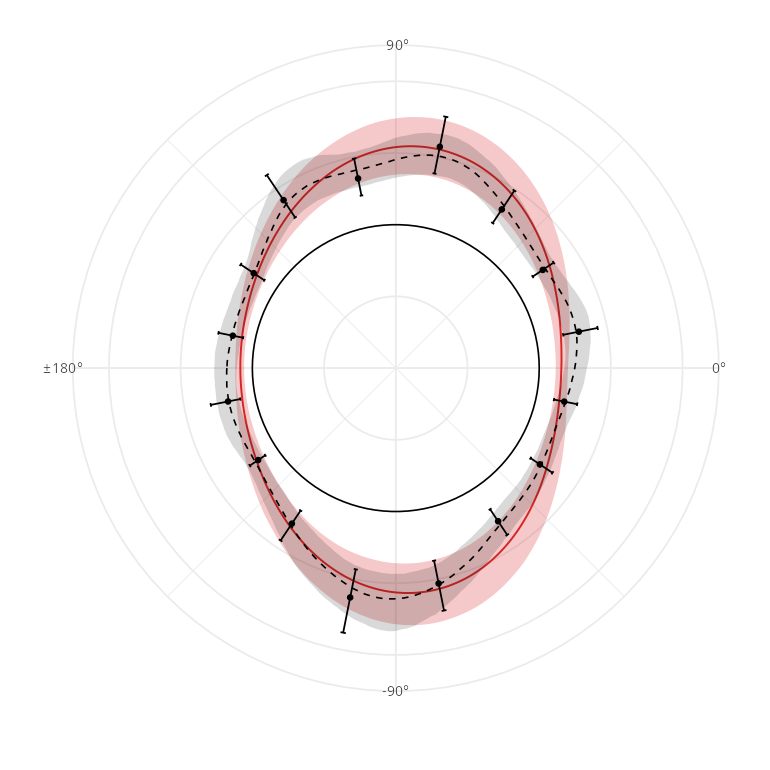

In [23]:
# Angle ticks use the twin's degree labels (locust_direction_plots.py):
# the mathematical orientation (0 at 3 o'clock, counter-clockwise) is the
# twin default for this x range, and the density-zero ring at radius 0.5
# is drawn as a black circle, as in the twin.
edge_radius <- 0.5
p_validation_polar <- ggplot(model_density, aes(theta, edge_radius + center)) +
  geom_ribbon(aes(ymin = edge_radius + low, ymax = edge_radius + high), fill = RED, alpha = 0.25) +
  geom_line(colour = RED, linewidth = 0.6) +
  geom_ribbon(data = kde_density, aes(ymin = edge_radius + low, ymax = edge_radius + high),
              fill = "black", alpha = 0.15) +
  geom_line(data = kde_density, linetype = "dashed", linewidth = 0.5) +
  geom_errorbar(data = hist_density, aes(ymin = edge_radius + low, ymax = edge_radius + high), width = 0.02) +
  geom_point(data = hist_density, size = 1.3) +
  geom_hline(yintercept = edge_radius, colour = "black", linewidth = 0.5) +
  scale_x_continuous(limits = c(-pi, pi),
                     breaks = c(-pi / 2, 0, pi / 2, pi),
                     labels = c("-90°", "0°", " 90°", "±180°     "),
                     expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, edge_radius + max(model_density$high, kde_density$high) * 1.2)) +
  coord_polar(start = pi / 2, direction = -1) +
  # The twin shows no axis labels; keep blank radius tick labels like it.
  labs(x = "", y = "") +
  theme(axis.text.y = element_blank(), axis.ticks.y = element_blank())
p_validation_polar <- p_validation_polar | val_legend(framed = TRUE)
p_validation_polar <- p_validation_polar + plot_layout(widths = c(4, 1))
save_figure(p_validation_polar, "population_directional_validation", 7, 7)

## Individual-level posterior predictive checks

The individual-level posterior predictive check compares each animal's observed headings with the posterior predictive density of the fitted model. Arrows mark the two mixture-component mean directions, scaled by each component's contribution to the expected resultant vector (its mixture weight times its mean resultant length); inward residuals scale the pointwise lack of fit against the local predictive density.


The component arrows and the plug-in mean direction use the wrapped
arithmetic mean of the component means (arithmetic angle mean followed by
wrapping), not the circular mean. The 95% band is
computed from complete posterior density draws. Residual ticks use the
inverse plug-in density normalized by its trapezoidal integral, and point
outward for observations and inward for residuals. Animal labels are 1–52
in the figures, corresponding to dense data IDs 0–51.


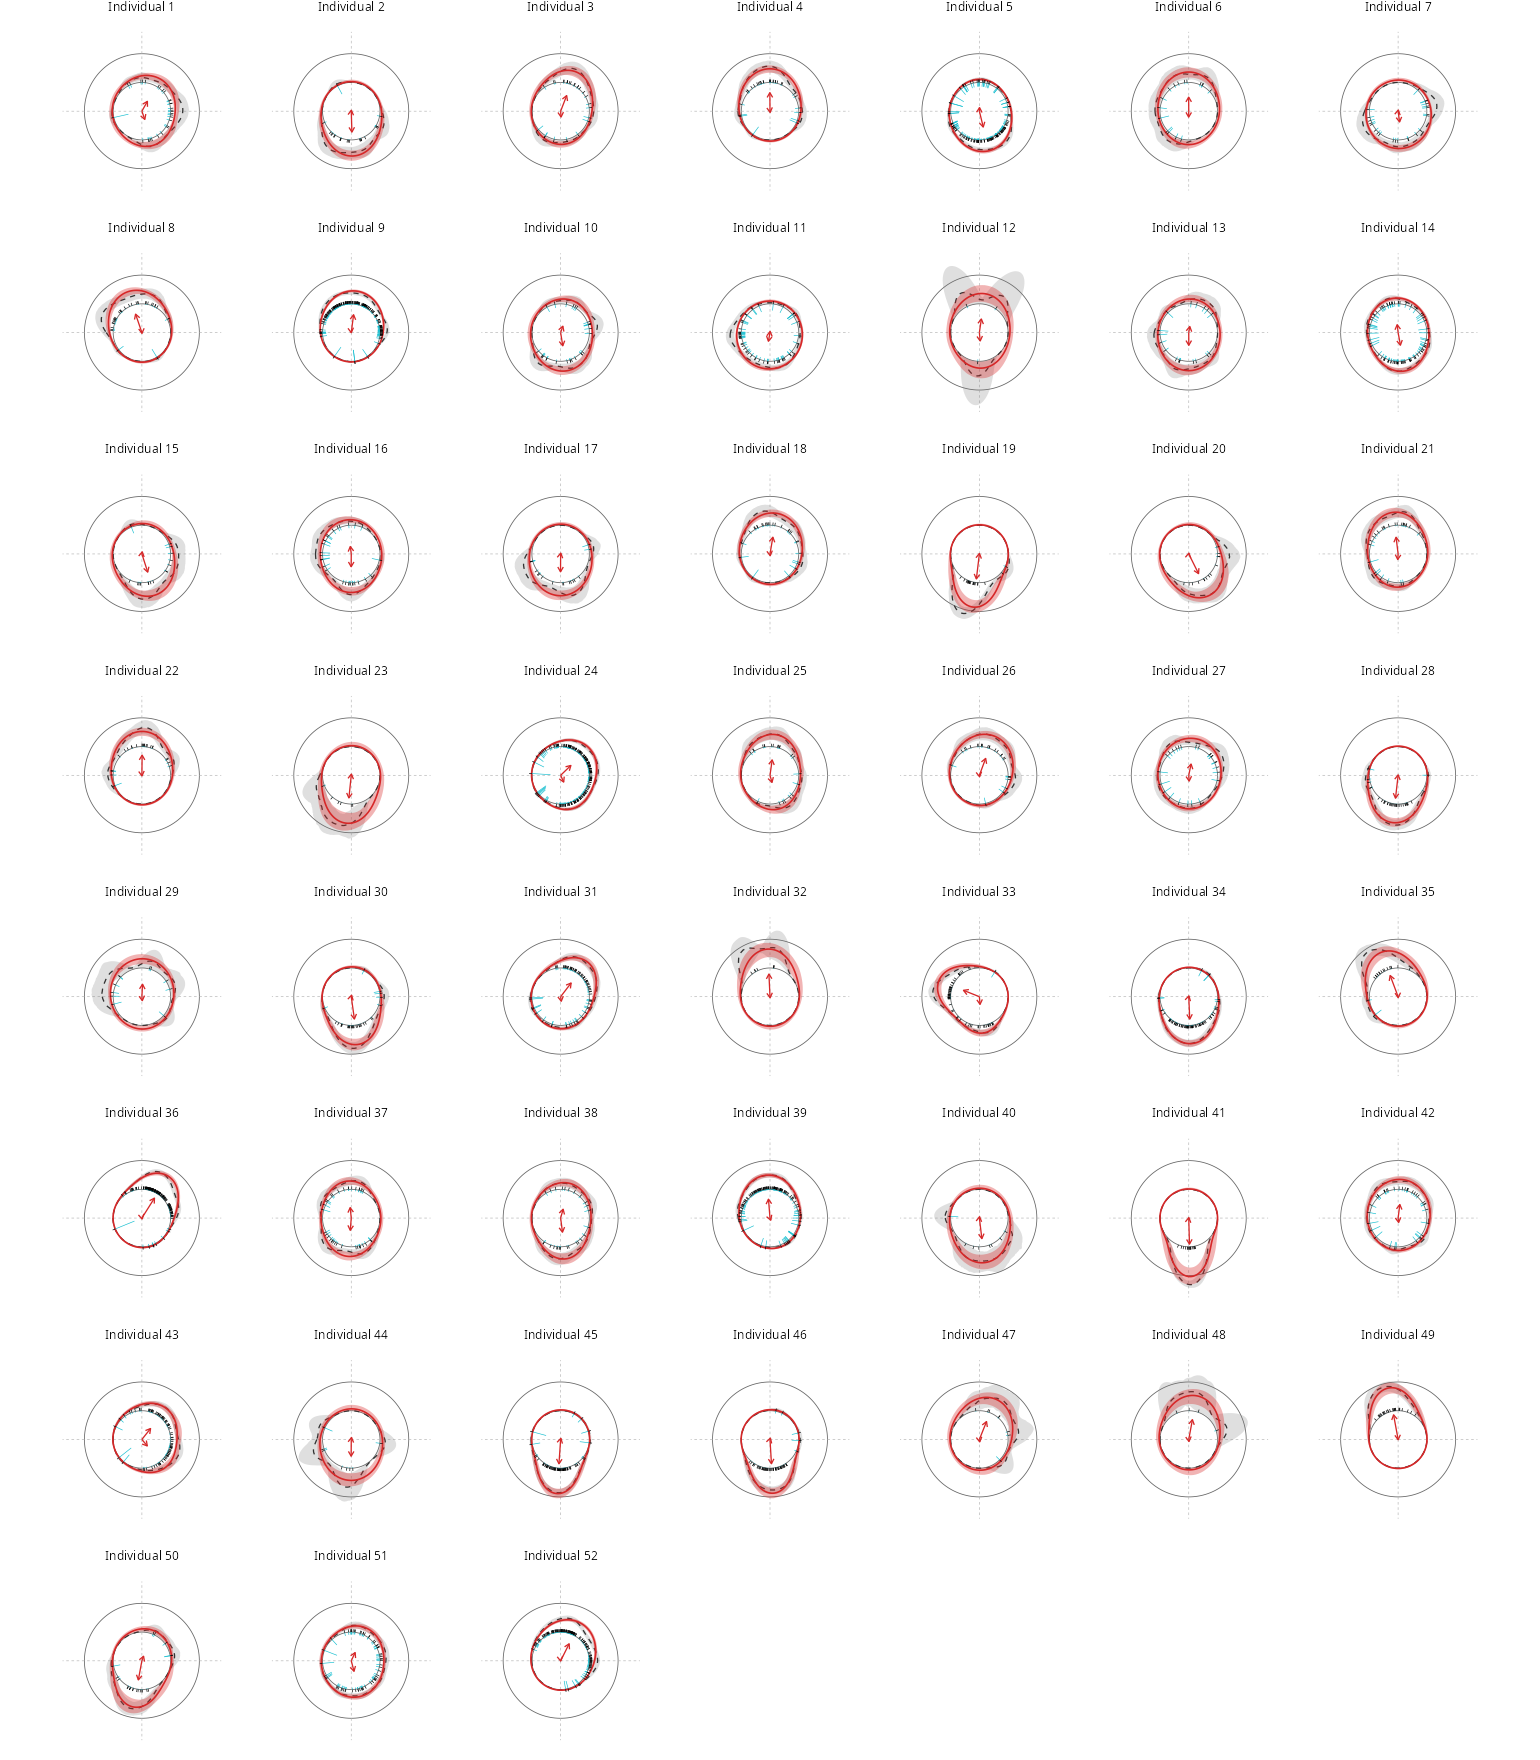

In [24]:
individual_theta <- -pi + (0:359) * (2 * pi / 360)
individual_curves <- vector("list", num_individuals)
individual_ticks <- vector("list", num_individuals)
individual_arrows <- vector("list", num_individuals)
for (i in seq_len(num_individuals)) {
  y <- wrap(df$direction[rows_by_animal[[i]]])
  mu <- rbind(state_bimodal$muone[i, ], state_bimodal$mutwo[i, ])
  kappa <- rbind(state_bimodal$kone[i, ], state_bimodal$ktwo[i, ])
  weight <- state_bimodal$weight[i, ]
  pdf <- mixture_grid(individual_theta, mu, kappa, clip_mixture_weight(weight))
  bounds <- t(apply(pdf, 1, quantile, probs = c(0.025, 0.975)))
  # Source semantics: PDF of posterior mean parameters, not mean PDF.
  mu_mean <- wrap(rowMeans(mu))
  kappa_mean <- rowMeans(kappa)
  w_mean <- clip_mixture_weight(mean(weight))
  plugin <- as.numeric(mixture_grid(individual_theta,
    matrix(mu_mean, ncol = 1L), matrix(kappa_mean, ncol = 1L), w_mean))
  kernel <- kde_basis(individual_theta, y, bw = 15)
  boot <- matrix(0, nrow = length(individual_theta), ncol = N_BOOT_KDE)
  set.seed(123L + 10000L + i - 1L)
  for (b in seq_len(N_BOOT_KDE)) {
    boot[, b] <- rowMeans(kernel[, sample.int(length(y), length(y), replace = TRUE), drop = FALSE])
  }
  kde <- t(apply(boot, 1, quantile, probs = c(0.025, 0.5, 0.975)))
  curve <- data.frame(individual = i, theta = individual_theta,
    model = plugin, model_low = bounds[, 1], model_high = bounds[, 2],
    kde_low = kde[, 1], kde = kde[, 2], kde_high = kde[, 3])
  # Close the periodic curve explicitly with the first grid value.
  end <- curve[1, ]
  end$theta <- pi
  individual_curves[[i]] <- rbind(curve, end)
  inv_grid <- 1 / plugin
  integral <- sum(diff(individual_theta) *
                  (head(inv_grid, -1L) + tail(inv_grid, -1L)) / 2)
  at_data <- as.numeric(mixture_grid(y, matrix(mu_mean, ncol = 1L),
                                     matrix(kappa_mean, ncol = 1L), w_mean))
  individual_ticks[[i]] <- data.frame(individual = i, theta = y,
    residual = -1 / (at_data * (integral + 1e-12)))
  individual_arrows[[i]] <- data.frame(individual = i, theta = mu_mean,
    length = c(w_mean, 1 - w_mean) * A1_safe(kappa_mean))
}
ppc_curves <- do.call(rbind, individual_curves)
ppc_ticks <- do.call(rbind, individual_ticks)
ppc_arrows <- do.call(rbind, individual_arrows)
ppc_levels <- seq_len(num_individuals)
for (name in c("ppc_curves", "ppc_ticks", "ppc_arrows")) {
  object <- get(name)
  object$individual <- factor(object$individual, levels = ppc_levels,
                              labels = paste("Individual", ppc_levels))
  assign(name, object)
}
rmax <- max(2, 1 + max(ppc_curves$model_high, ppc_curves$kde_high) * 1.15)
p_individual_ppc <- ggplot(ppc_curves, aes(theta, 1 + model, group = individual)) +
  geom_hline(yintercept = c(1, 2), colour = "grey40", linewidth = 0.25) +
  geom_vline(xintercept = c(-pi, -pi / 2, 0, pi / 2), colour = "grey70", linetype = "dashed", linewidth = 0.2) +
  geom_ribbon(aes(ymin = 1 + kde_low, ymax = 1 + kde_high), fill = "grey50", alpha = 0.25) +
  geom_line(aes(y = 1 + kde), colour = "grey20", linetype = "dashed", linewidth = 0.4) +
  geom_ribbon(aes(ymin = 1 + model_low, ymax = 1 + model_high), fill = RED, alpha = 0.35) +
  geom_line(colour = RED, linewidth = 0.5) +
  geom_segment(data = ppc_ticks,
    aes(x = theta, xend = theta, y = 1, yend = 1.1), inherit.aes = FALSE, linewidth = 0.2) +
  geom_segment(data = ppc_ticks,
    aes(x = theta, xend = theta, y = 1, yend = pmax(0, 1 + residual)),
    inherit.aes = FALSE, colour = "#17BECF", linewidth = 0.2) +
  geom_segment(data = ppc_arrows,
    aes(x = theta, xend = theta, y = 0, yend = length), inherit.aes = FALSE,
    colour = RED, linewidth = 0.4, arrow = grid::arrow(length = grid::unit(0.05, "inches"))) +
  scale_x_continuous(limits = c(-pi, pi), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, rmax), expand = c(0, 0)) +
  coord_polar(start = pi / 2, direction = -1) +
  facet_wrap(~ individual, ncol = 7) + theme_void(base_size = 8) +
  theme(strip.text = element_text(size = 8), panel.spacing = grid::unit(0.5, "lines"))
save_figure(p_individual_ppc, "locust_directional_individual_ppc", 14, 16)

### Replicated headings for both models

Replicate the observed number of heading steps for each of the 52 animals
using one shared posterior draw per replicate. Draw the bimodal
component from the animal's mixture weight, then draw a von Mises
heading from that component. The unimodal fit draws from its single
component. Wrap each replicated heading to the circle before binning or
smoothing it. Population checks average per-animal densities with equal
weight, as in the observed bootstrap. Individual checks retain the
animal-specific densities. These checks complement the analytic-density figures above.

In [25]:
# The 52 animal sections of the predictive check are independent, so
# they run on a PSOCK cluster (fresh child R processes) instead of
# in the kernel. Workers are seeded per (model, animal), so results do
# not depend on the core count. (The earlier parallelize attempt used
# parallel::mclapply, whose fork is not safe under IRkernel: workers
# inherit the kernel's live ZMQ socket and the fork corrupts it. This
# also re-seeds the PPC draw streams relative to the original
# shared-stream implementation; the values move by Monte Carlo noise
# only, and the in-notebook gates are on the fit, not on these draws.
# The workers are plain top-level functions, which serialize as
# ~50-byte closures over the globalenv; all data flows through the
# explicit parLapply arguments.)
ppc_worker <- function(i, state, draws, n, theta_grid, bins, bin_widths,
                       bin_centers, rng_seed) {
  wrap <- function(x) (x + pi) %% (2 * pi) - pi
  circular_kde <- function(theta, y, bw) {
    yc <- circular::circular(wrap(y), units = "radians", template = "none",
                             modulo = "asis")
    z <- circular::circular(theta, units = "radians", template = "none",
                            modulo = "asis")
    circular::density.circular(yc, z = z, bw = bw,
                               kernel = "vonmises")$y
  }
  bin_heading_density <- function(y) {
    b <- findInterval(wrap(y), bins, rightmost.closed = TRUE)
    tabulate(b, nbins = length(bin_centers)) /
      (length(y) * bin_widths)
  }
  draw_vm <- function(n, mu, kappa) {
    if (!n) return(numeric())
    vmu <- circular::circular(mu, units = "radians", template = "none",
                              modulo = "2pi")
    as.numeric(circular::rvonmises(n, vmu, kappa,
      control.circular = list(units = "radians", template = "none",
                              modulo = "2pi")))
  }
  if (is.null(state$weight)) {
    rep_head <- function(draw) {
      wrap(draw_vm(n, state$muone[i, draw], state$kone[i, draw]))
    }
  } else {
    rep_head <- function(draw) {
      first <- rbinom(1, n, state$weight[i, draw])
      wrap(c(draw_vm(first, state$muone[i, draw], state$kone[i, draw]),
             draw_vm(n - first, state$mutwo[i, draw], state$ktwo[i,
               draw])))
    }
  }
  set.seed(rng_seed)
  y_rep <- lapply(draws, rep_head)
  list(hist = vapply(y_rep, bin_heading_density,
                     numeric(length(bin_centers))),
    population = vapply(y_rep, function(y) {
      circular_kde(theta_grid, y, bw = 30)
    }, numeric(length(theta_grid))),
    individual = vapply(y_rep, function(y) {
      circular_kde(theta_grid, y, bw = 15)
    }, numeric(length(theta_grid))))
}
ppc_task <- function(i, state, draws, n_all, theta_grid, bins,
                     bin_widths, bin_centers, rng_tag) {
  ppc_worker(i, state, draws, n_all[i], theta_grid, bins, bin_widths,
             bin_centers, rng_tag + i)
}
predictive_checks <- function(state, model, model_tag) {
  draws <- sample.int(nrow(state$draws), N_PREDICTIVE)
  n_all <- vapply(rows_by_animal, length, integer(1L))
  ppc_cores <- min(8L, max(2L, parallel::detectCores()))
  cl <- parallel::makePSOCKcluster(ppc_cores)
  on.exit(parallel::stopCluster(cl), add = TRUE)
  parallel::clusterEvalQ(cl, quote({
    .libPaths(c(Filter(nzchar, c(Sys.getenv("R_LIBS_USER"),
      Sys.getenv("R_LIBS_SITE"))), .libPaths()))
  }))
  parallel::clusterExport(cl, c("ppc_worker", "ppc_task"),
                          envir = globalenv())
  individuals <- parallel::parLapply(
    cl, seq_len(num_individuals), ppc_task,
    state = state, draws = draws, n_all = n_all, theta_grid = theta_grid,
    bins = bins, bin_widths = bin_width, bin_centers = bin_centers,
    rng_tag = SEED + 90000L + 1000L * model_tag)
  pop_hist <- matrix(0, nrow = length(bin_centers), ncol = length(draws))
  pop_kde <- matrix(0, nrow = length(theta_grid), ncol = length(draws))
  for (ind in individuals) {
    pop_hist <- pop_hist + ind$hist / num_individuals
    pop_kde <- pop_kde + ind$population / num_individuals
  }
  stopifnot(all(abs(colSums(pop_hist) * bin_width - 1) < 1e-10))
  population <- rbind(
    transform(density_frame(bin_centers, pop_hist), estimate = "Histogram"),
    transform(density_frame(theta_grid, pop_kde), estimate = "Von Mises KDE"))
  individual <- do.call(rbind, lapply(seq_along(individuals), function(i) {
    transform(density_frame(theta_grid, individuals[[i]]$individual),
              individual = paste("Individual", i))
  }))
  list(population = transform(population, model = model),
       individual = transform(individual, model = model))
}
set.seed(SEED + 1L)
ppc_bimodal <- predictive_checks(state_bimodal, "Bimodal", model_tag = 1L)
set.seed(SEED + 2L)
ppc_unimodal <- predictive_checks(state_unimodal, "Unimodal", model_tag = 2L)


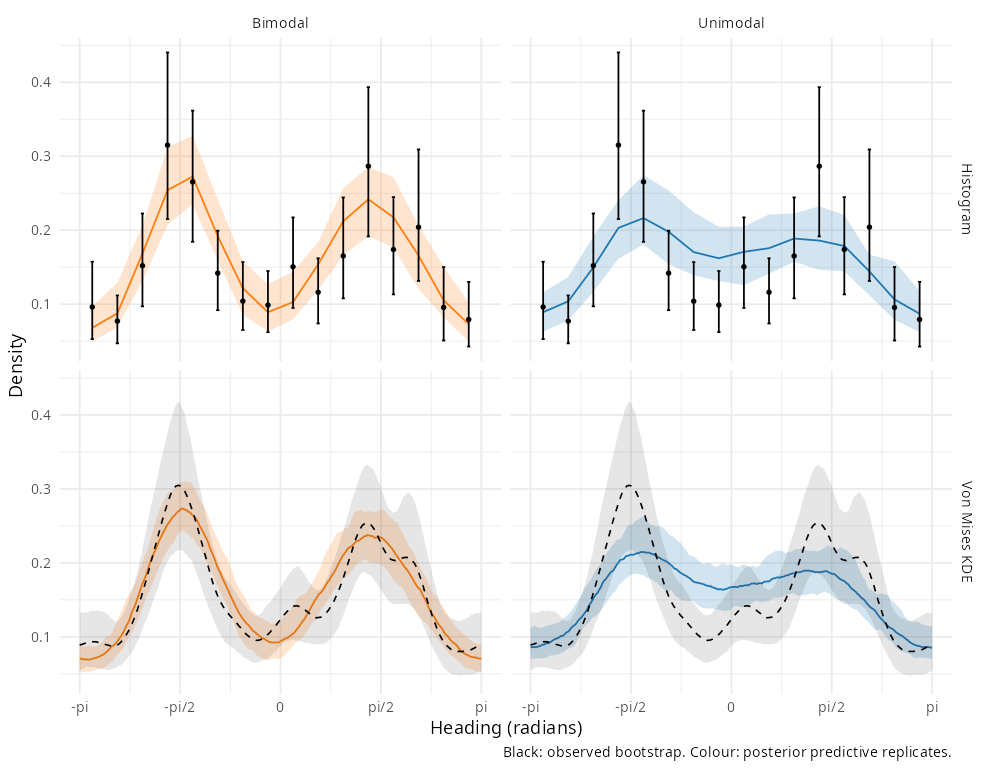

In [26]:
population_predictive <- rbind(ppc_bimodal$population, ppc_unimodal$population)
observed_hist <- transform(hist_density, estimate = "Histogram")
observed_kde <- transform(kde_density, estimate = "Von Mises KDE")
p_population_predictive <- ggplot(population_predictive, aes(theta, center)) +
  geom_ribbon(aes(ymin = low, ymax = high, fill = model), alpha = 0.2) +
  geom_line(aes(colour = model), linewidth = 0.55) +
  geom_errorbar(data = observed_hist, aes(ymin = low, ymax = high), width = 0.05) +
  geom_point(data = observed_hist, size = 1) +
  geom_ribbon(data = observed_kde, aes(ymin = low, ymax = high), alpha = 0.12) +
  geom_line(data = observed_kde, linetype = "dashed", linewidth = 0.5) +
  scale_colour_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_fill_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_x_continuous(breaks = angle_breaks, labels = angle_labels) +
  facet_grid(estimate ~ model) +
  labs(x = "Heading (radians)", y = "Density",
    caption = "Black: observed bootstrap. Colour: posterior predictive replicates.") +
  theme(legend.position = "none")
save_figure(p_population_predictive, "population_predictive_both_models", 9, 7)

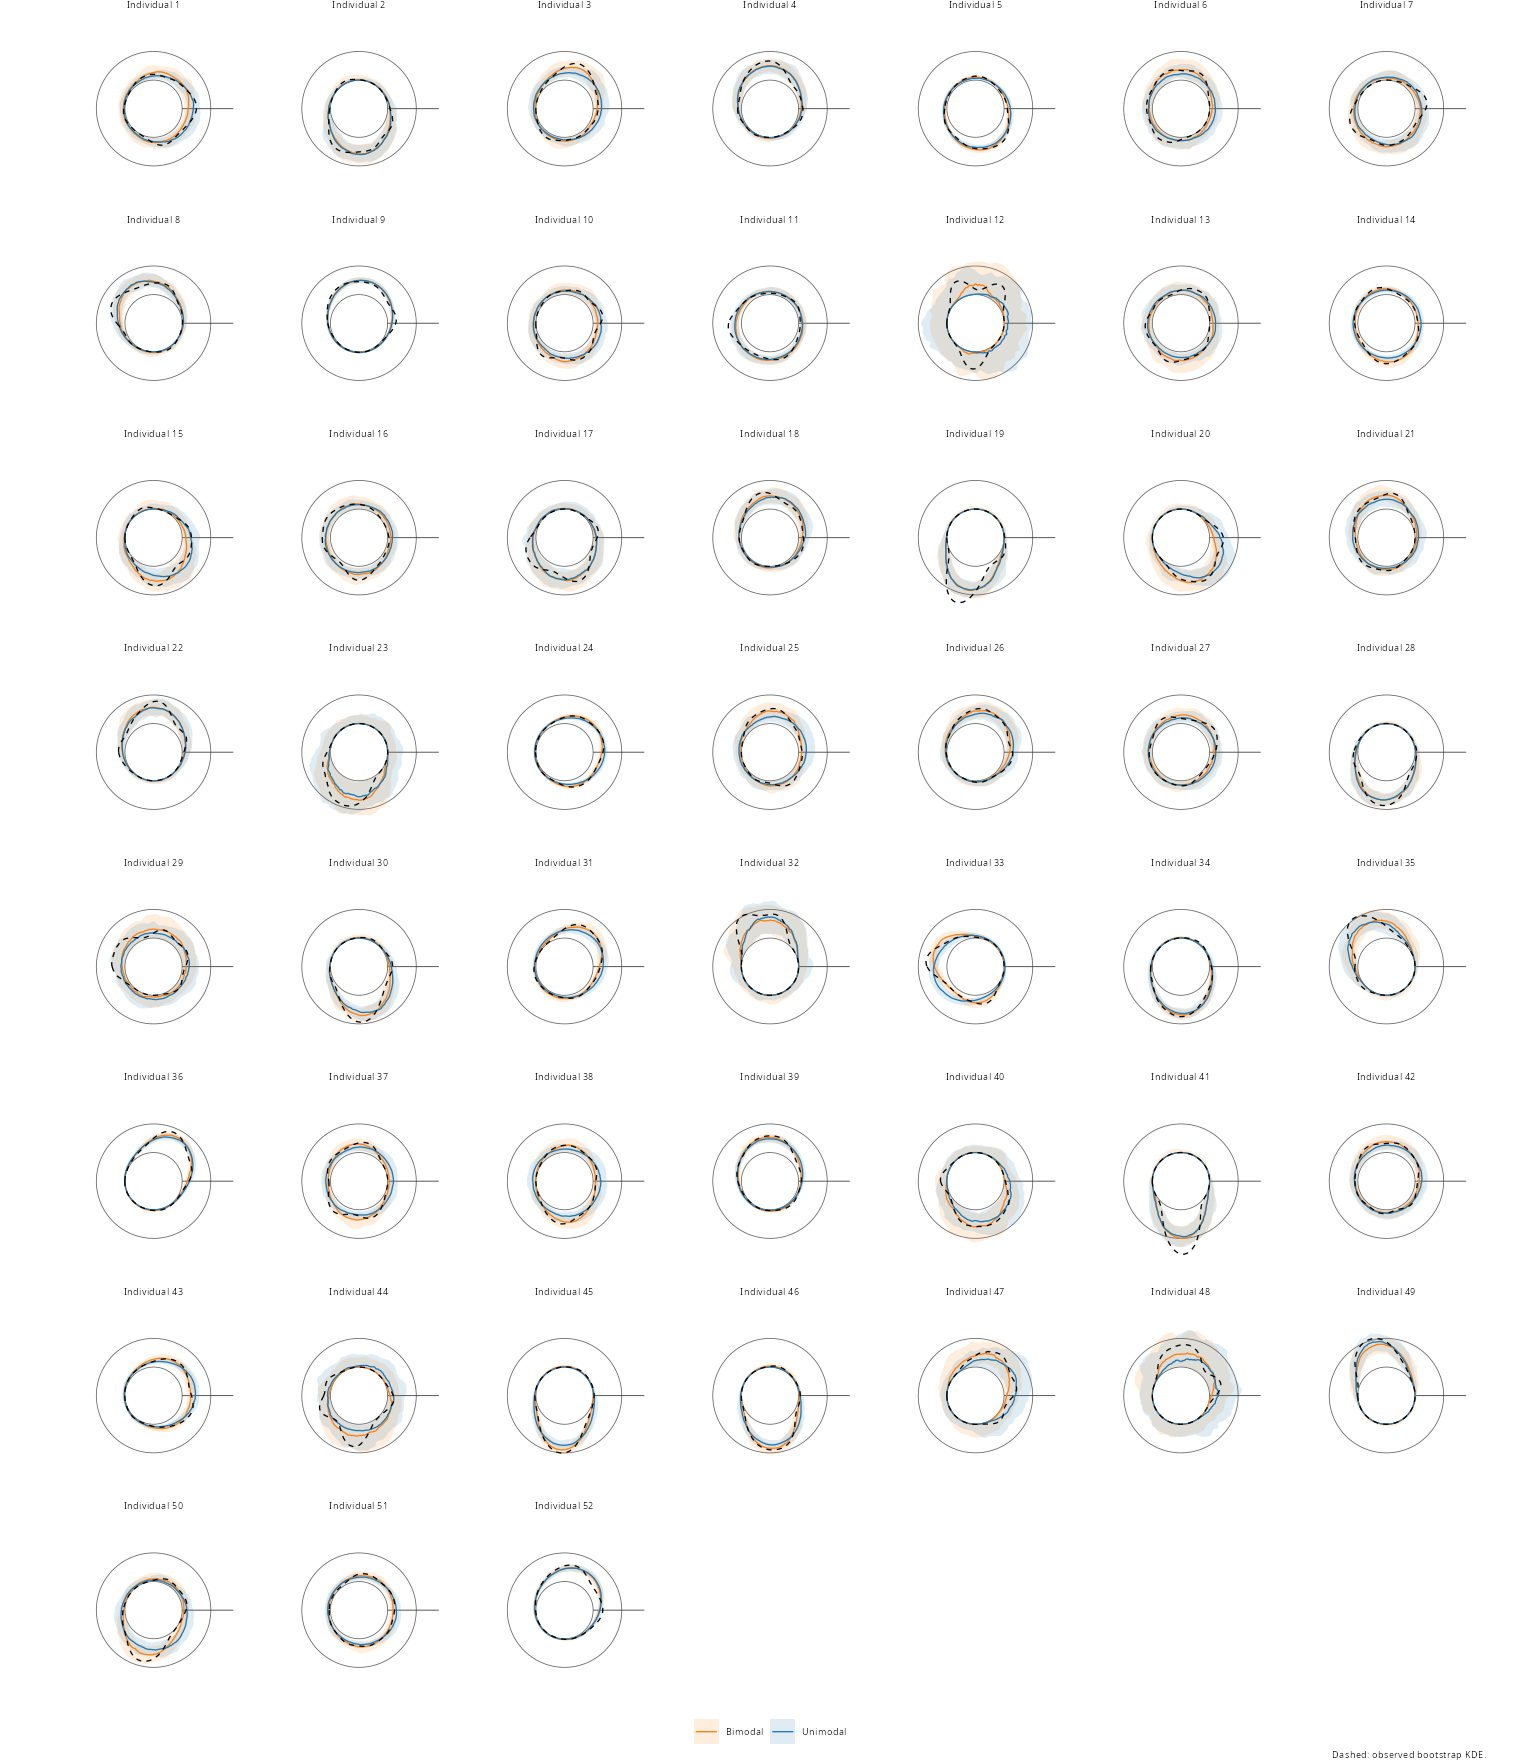

In [27]:
individual_predictive <- rbind(ppc_bimodal$individual, ppc_unimodal$individual)
individual_predictive$individual <- factor(individual_predictive$individual,
                                            levels = levels(ppc_curves$individual))
# Same radius convention as the other polar figures: density zero sits on
# the ring at radius 1 and the shared peak (largest model centre density
# over all individuals and both models) on the ring at radius 2, so the
# two models' peaks are directly comparable across the grid; the dashed
# observed bootstrap KDE is drawn on the same radius.
peak_max_ppc <- max(individual_predictive$center)
individual_predictive$r_low <- 1 + individual_predictive$low / peak_max_ppc
individual_predictive$r_center <- 1 + individual_predictive$center / peak_max_ppc
individual_predictive$r_high <- 1 + individual_predictive$high / peak_max_ppc
ppc_curves$kde_r <- 1 + ppc_curves$kde / peak_max_ppc
rmax_ppc <- max(2, 1 + 1.15 * max(individual_predictive$high,
  ppc_curves$kde) / peak_max_ppc)
p_individual_predictive <- ggplot(individual_predictive,
  aes(theta, r_center)) +
  geom_hline(yintercept = c(1, 2), colour = "grey40", linewidth = 0.25) +
  geom_segment(data = data.frame(x = 0, xend = 0, y = 1, yend = rmax_ppc),
    inherit.aes = FALSE,
    aes(x = x, xend = xend, y = y, yend = yend),
    colour = "grey20", linewidth = 0.25) +
  geom_ribbon(aes(ymin = r_low, ymax = r_high, fill = model), alpha = 0.14) +
  geom_line(aes(colour = model), linewidth = 0.4) +
  geom_line(data = ppc_curves, aes(y = kde_r),
    linetype = "dashed", linewidth = 0.4) +
  scale_colour_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_fill_manual(values = c(Bimodal = ORANGE, Unimodal = BLUE)) +
  scale_x_continuous(limits = c(-pi, pi), expand = c(0, 0)) +
  scale_y_continuous(limits = c(0, rmax_ppc), expand = c(0, 0)) +
  coord_polar(start = pi / 2, direction = -1) +
  facet_wrap(~ individual, ncol = 7) + theme_void(base_size = 8) +
  labs(colour = NULL, fill = NULL, caption = "Dashed: observed bootstrap KDE.") +
  theme(legend.position = "bottom")
save_figure(p_individual_predictive, "individual_predictive_both_models", 14, 16)

## Bayesian hypothesis tests

This section quantifies how much **posterior predictive density** falls near the theory-predicted directions, relative to a uniform baseline:

1. **Optic flow (forward) hypothesis** ($y = 0$): the locusts align with the wide-field motion and keep marching forward.
2. **Vectorial encoding (lateral) hypothesis** ($y = \pm \frac{\pi}{2}$): the locusts commit to one of the two lateral virtual swarms.
3. **Random walk baseline**: uniform density $p_{\text{unif}} = 1/(2\pi)$ - no directional bias.

**Model definition for the hypothesis tests.** Using the posterior samples, we construct the **population-level mixture model** by setting the individual offsets to zero, so the model is described by the **population-level parameter vector** $ \Theta_0 = \{\omega_0, \boldsymbol{\kappa}_0, \boldsymbol{\mu}_0\} $, where:
- $ \omega_0 $ is the mixture weight for the two directional modes,
- $ \boldsymbol{\kappa}_0 = \{\kappa_{0,1}, \kappa_{0,2}\} $ are the component concentrations, and
- $ \boldsymbol{\mu}_0 = \{\mu_{0,1}, \mu_{0,2}\} $ are the component mean directions.

The **posterior predictive density** is the normalized componentwise mixture

$$
p(y \mid \Theta_0)
= \omega_0\,\mathcal M(y\mid\mu_{0,1},\kappa_{0,1})
+ (1-\omega_0)\,\mathcal M(y\mid\mu_{0,2},\kappa_{0,2}).
$$

**Hypothesis values.**

- **Optic flow (forward)**: $p_{\to} = p(y = 0 \mid \Theta_0)$.
- **Vectorial encoding (lateral)**: the per-mode average $p_{\updownarrow} = \frac{1}{2} \left[ p(y = \frac{\pi}{2} \mid \Theta_0) + p(y = -\frac{\pi}{2} \mid \Theta_0) \right]$; the total density assigned to the lateral hypothesis is twice the reported per-mode value, which keeps it directly comparable to the single-mode optic-flow value.
- Comparing both against the random walk baseline shows whether the fitted model supports a directional preference for forward or lateral movement.

The same evaluation is repeated per animal, using each animal's posterior parameter vector instead of $\Theta_0$.


The following figures evaluate density at the hypotheses and compare
weight-only alignment scores; these are distinct from the held-out-step
PSIS-LOO scores above. The hypothesis panels labeled “ELPD” report the mean
**per-draw log density at a fixed hypothesis direction**, with bars of
$1.96\,\mathrm{sd}(\log p)/\sqrt{N_{\text{draws}}}$ — not
effective-sample-size-adjusted posterior intervals.

For the lateral hypothesis, the two mode densities are combined as a
**per-mode average** (the log-sum of the two pointwise log densities minus
$\log 2$). The pooled individual-density row first averages the individual
**log** densities within each draw, then summarizes and exponentiates the
average; it is not an arithmetic mixture of individual densities. The
population row sets the animal offsets to zero and is therefore distinct
from this pooled row.

  individual    hypothesis    center        low      high probability
1          1    Optic flow 0.0771327 0.05817435 0.1009854           1
2          1 Vec. encoding 0.2771139 0.25280319 0.3021021           1


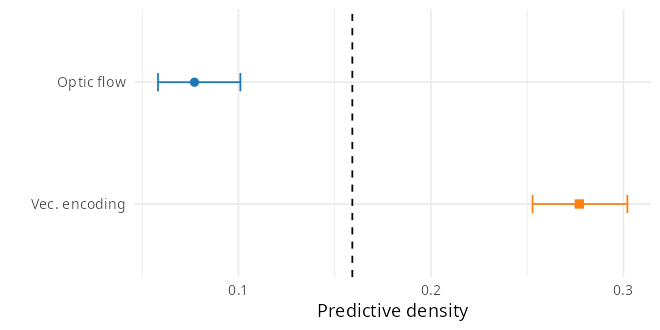

In [28]:
hypothesis_arrays <- function(state, clip = FALSE) {
  forward <- mixture_at(0, state, clip)
  left <- mixture_at(-pi / 2, state, clip)
  right <- mixture_at(pi / 2, state, clip)
  list(forward = forward, perpendicular = log_add(left, right) - log(2))
}
hyp_pop <- hypothesis_arrays(population_state)
hyp_ind <- hypothesis_arrays(state_bimodal, clip = TRUE)
interval_row <- function(x, mode = c("density", "elpd", "alignment")) {
  mode <- match.arg(mode)
  if (mode == "elpd") {
    center <- mean(x)
    error <- 1.96 * sd(x) / sqrt(length(x))
    return(c(center = center, low = center - error, high = center + error))
  }
  bounds <- hdi(x)
  if (mode == "density") {
    return(c(center = exp(median(x)), low = exp(unname(bounds[1])), high = exp(unname(bounds[2]))))
  }
  c(center = mean(x), low = unname(bounds[1]), high = unname(bounds[2]))
}
make_hyp_table <- function(arrays, mode, pooled = FALSE) {
  f <- arrays$forward
  p <- arrays$perpendicular
  stopifnot(is.matrix(f), identical(dim(f), dim(p)))
  labels <- as.character(seq_len(nrow(f)))
  if (pooled) {
    f <- rbind(f, colMeans(f))
    p <- rbind(p, colMeans(p))
    labels <- c(labels, "Pooled")
  }
  do.call(rbind, lapply(seq_len(nrow(f)), function(i) {
    z <- rbind(interval_row(f[i, ], mode), interval_row(p[i, ], mode))
    data.frame(individual = labels[i], hypothesis = c("Optic flow", "Vec. encoding"),
      center = z[, 1], low = z[, 2], high = z[, 3],
      probability = mean(p[i, ] > f[i, ]), row.names = NULL)
  }))
}
population_dots <- function(table, label, baseline, invert = FALSE) {
  levels <- if (invert) c("Optic flow", "Vec. encoding")
          else c("Vec. encoding", "Optic flow")
  ggplot(table, aes(center, factor(hypothesis, levels = levels),
          colour = hypothesis, shape = hypothesis)) +
    geom_errorbar(aes(xmin = low, xmax = high), orientation = "y", width = 0.15) +
    geom_point(size = 2.5) + geom_vline(xintercept = baseline, linetype = "dashed") +
    scale_colour_manual(values = HYP_COLORS) +
    scale_shape_manual(values = c("Optic flow" = 16, "Vec. encoding" = 15)) +
    labs(x = label, y = "") + theme(legend.position = "none")
}
individual_dots <- function(table, label, baseline, limits = NULL) {
  labels <- unique(table$individual)
  table$individual <- factor(table$individual, levels = rev(labels))
  dodge <- position_dodge(width = 0.5)
  main <- ggplot(table, aes(center, individual, colour = hypothesis, shape = hypothesis)) +
    geom_errorbar(aes(xmin = low, xmax = high), orientation = "y", width = 0.2, position = dodge) +
    geom_point(size = 1.6, position = dodge) +
    geom_vline(xintercept = baseline, linetype = "dashed") +
    scale_colour_manual(values = HYP_COLORS) +
    scale_shape_manual(values = c("Optic flow" = 16, "Vec. encoding" = 15)) +
    labs(x = label, y = "Individual", tag = "a.") +
    theme(legend.position = "top",
          legend.background = element_rect(fill = "white", colour = "grey50"))
  if (!is.null(limits)) main <- main + coord_cartesian(xlim = limits)
  probs <- table[!duplicated(table$individual), ]
  probability <- ggplot(probs, aes(probability, individual)) +
    geom_point(size = 1.6) + geom_vline(xintercept = 0.5, linetype = "dashed") +
    geom_vline(xintercept = 1) + scale_x_continuous(limits = c(0, 1.02)) +
    labs(x = "P(Vec. encoding > Optic flow)", y = "", tag = "b.") +
    theme(axis.text.y = element_blank(), axis.ticks.y = element_blank())
  main + probability + plot_layout(widths = c(1.35, 1))
}
pop_density_table <- make_hyp_table(hyp_pop, "density")
print(pop_density_table)
save_figure(population_dots(pop_density_table, "Predictive density", 1 / (2 * pi)),
  "locust_directional_hypothesis_horizontal", 6, 3)

  individual    hypothesis    center       low      high probability
1          1    Optic flow -2.566744 -2.568964 -2.564524           1
2          1 Vec. encoding -1.284614 -1.285327 -1.283900           1


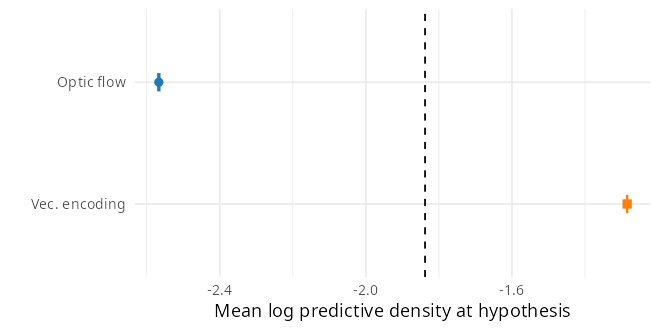

In [29]:
pop_elpd_table <- make_hyp_table(hyp_pop, "elpd")
print(pop_elpd_table)
save_figure(population_dots(pop_elpd_table, "Mean log predictive density at hypothesis", -log(2 * pi)),
  "locust_directional_hypothesis_horizontal_elpd", 6, 3)


    individual    hypothesis      center          low       high probability
1            1    Optic flow 0.182421862 0.1184637175 0.29280716   0.5781250
2            1 Vec. encoding 0.194751839 0.1518461839 0.25491415   0.5781250
3            2    Optic flow 0.058609371 0.0182910595 0.14425793   0.9996250
4            2 Vec. encoding 0.283345336 0.2098531662 0.37471593   0.9996250
5            3    Optic flow 0.104248268 0.0468391326 0.20424334   0.9735000
6            3 Vec. encoding 0.253903622 0.1905669114 0.33513780   0.9735000
7            4    Optic flow 0.080589076 0.0373449933 0.15299171   0.9991875
8            4 Vec. encoding 0.244733881 0.1931807300 0.30913238   0.9991875
9            5    Optic flow 0.112325519 0.0762602611 0.15801842   0.9996875
10           5 Vec. encoding 0.244578025 0.2084804792 0.28267451   0.9996875
11           6    Optic flow 0.090146401 0.0245473545 0.18241227   0.9782500
12           6 Vec. encoding 0.231213231 0.1591610448 0.31795480   0.9782500

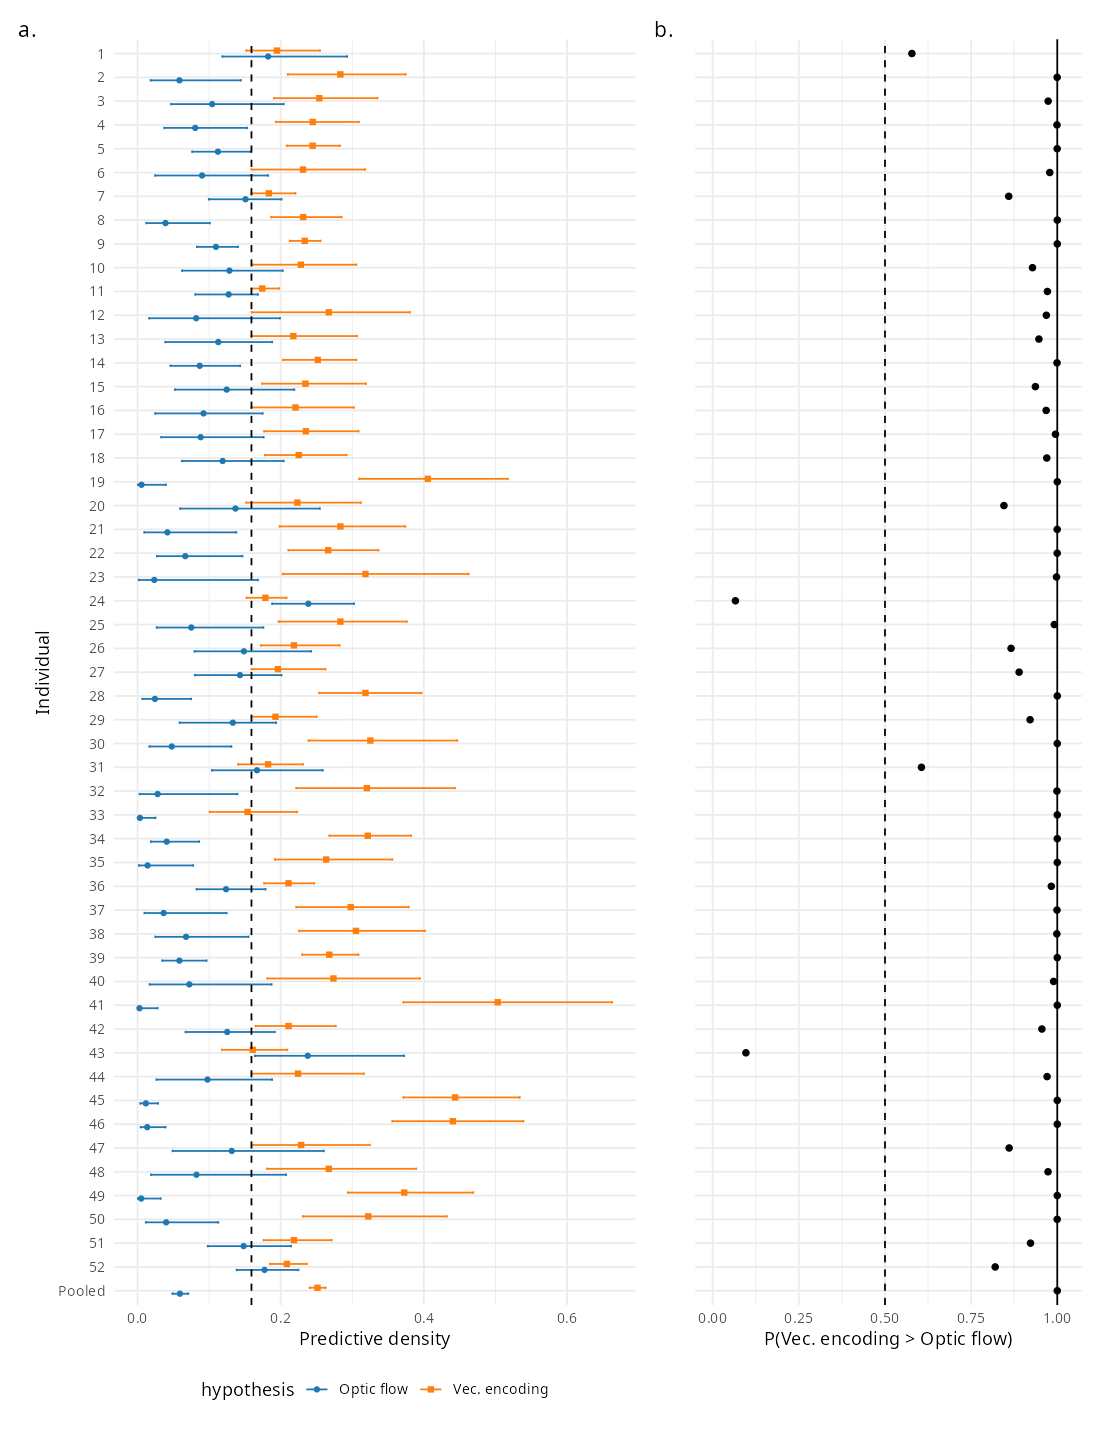

In [30]:
individual_density_table <- make_hyp_table(hyp_ind, "density", pooled = TRUE)
print(individual_density_table)
save_figure(individual_dots(individual_density_table, "Predictive density", 1 / (2 * pi)),
  "locust_directional_hypothesis_individual_ab", 10, 13)


    individual    hypothesis     center        low       high probability
1            1    Optic flow -1.6973527 -1.7008599 -1.6938455   0.5781250
2            1 Vec. encoding -1.6369155 -1.6390039 -1.6348271   0.5781250
3            2    Optic flow -2.9024702 -2.9110020 -2.8939385   0.9996250
4            2 Vec. encoding -1.2657552 -1.2680788 -1.2634316   0.9996250
5            3    Optic flow -2.2974108 -2.3033780 -2.2914435   0.9735000
6            3 Vec. encoding -1.3793617 -1.3816288 -1.3770947   0.9735000
7            4    Optic flow -2.5500596 -2.5557763 -2.5443429   0.9991875
8            4 Vec. encoding -1.4046379 -1.4065017 -1.4027742   0.9991875
9            5    Optic flow -2.1948202 -2.1977329 -2.1919074   0.9996875
10           5 Vec. encoding -1.4111031 -1.4123135 -1.4098927   0.9996875
11           6    Optic flow -2.5287922 -2.5377789 -2.5198056   0.9782500
12           6 Vec. encoding -1.4637799 -1.4667510 -1.4608088   0.9782500
13           7    Optic flow -1.922713

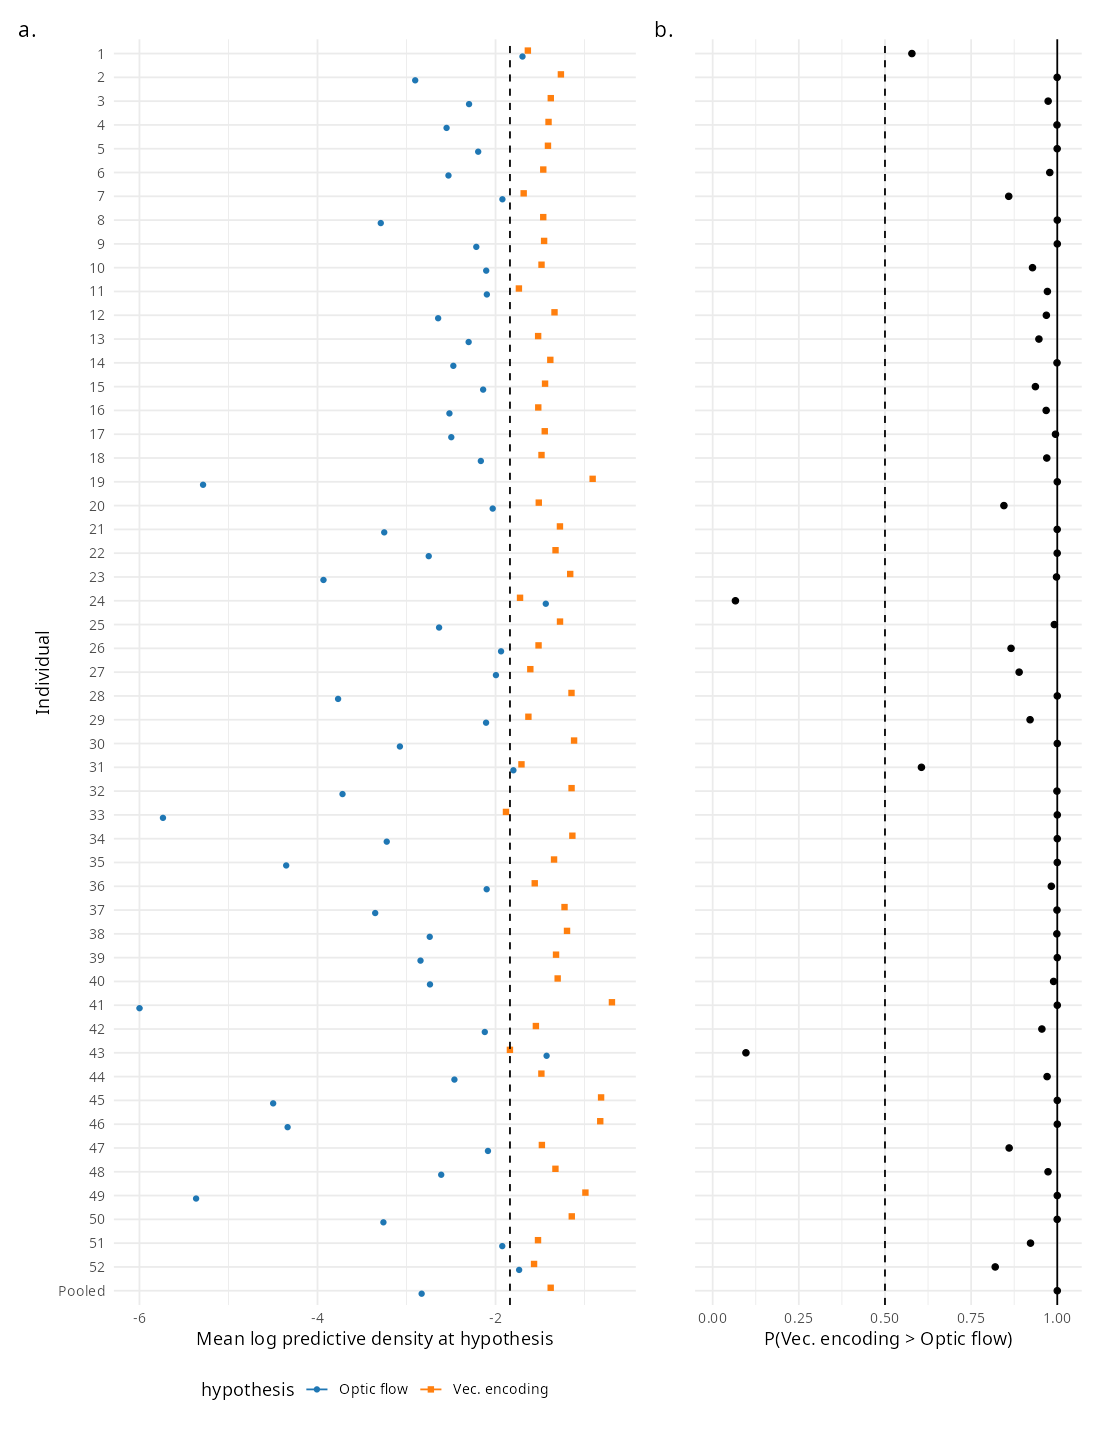

In [31]:
individual_elpd_table <- make_hyp_table(hyp_ind, "elpd", pooled = TRUE)
print(individual_elpd_table)
save_figure(individual_dots(individual_elpd_table, "Mean log predictive density at hypothesis", -log(2 * pi)),
  "locust_directional_hypothesis_individual_elpd_ab", 10, 13)


  individual    hypothesis    center        low      high probability
1          1    Optic flow 0.1331832 0.06153364 0.2054376           1
2          1 Vec. encoding 0.9574284 0.91497287 0.9936267           1


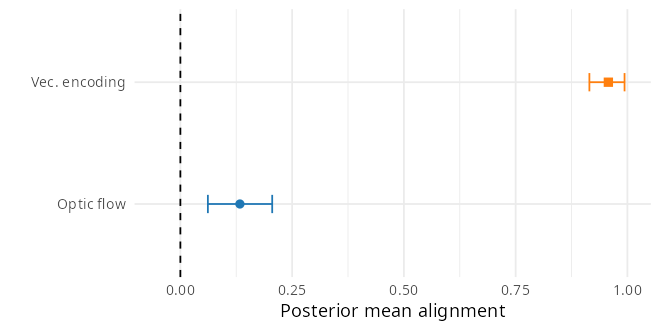

In [32]:
alignment_arrays <- function(state) {
  w <- state$weight
  stopifnot(is.matrix(w), identical(dim(w), dim(state$muone)))
  list(forward = w * cos(state$muone) + (1 - w) * cos(state$mutwo),
       perpendicular = w * cos(2 * (state$muone - pi / 2)) +
         (1 - w) * cos(2 * (state$mutwo - pi / 2)))
}
# Weight-only alignment is the source estimand; no A1(kappa) factor.
align_pop <- alignment_arrays(population_state)
align_ind <- alignment_arrays(state_bimodal)
pop_alignment_table <- make_hyp_table(align_pop, "alignment")
print(pop_alignment_table)
save_figure(population_dots(pop_alignment_table, "Posterior mean alignment", 0,
  invert = TRUE) +
              coord_cartesian(xlim = c(-0.05, 1)),
  "locust_directional_alignment_horizontal", 6, 3)


    individual    hypothesis        center          low         high
1            1    Optic flow  0.4595810039  0.160902831  0.741496502
2            1 Vec. encoding  0.4905246589 -0.021272383  0.996754825
3            2    Optic flow  0.0351754762 -0.195255002  0.287170480
4            2 Vec. encoding  0.9612183900  0.861881581  0.999999401
5            3    Optic flow  0.2856006613  0.070114746  0.497018999
6            3 Vec. encoding  0.7646929720  0.499396718  0.997383950
7            4    Optic flow  0.0005678127 -0.250472681  0.260429354
8            4 Vec. encoding  0.9583785068  0.853935003  0.999999957
9            5    Optic flow  0.2069407380  0.067716016  0.339282847
10           5 Vec. encoding  0.8854582875  0.760420433  0.995903710
11           6    Optic flow -0.0203135707 -0.348191462  0.311900918
12           6 Vec. encoding  0.9180532884  0.739478552  0.999999882
13           7    Optic flow  0.1402922958 -0.196988785  0.468655283
14           7 Vec. encoding  0.89

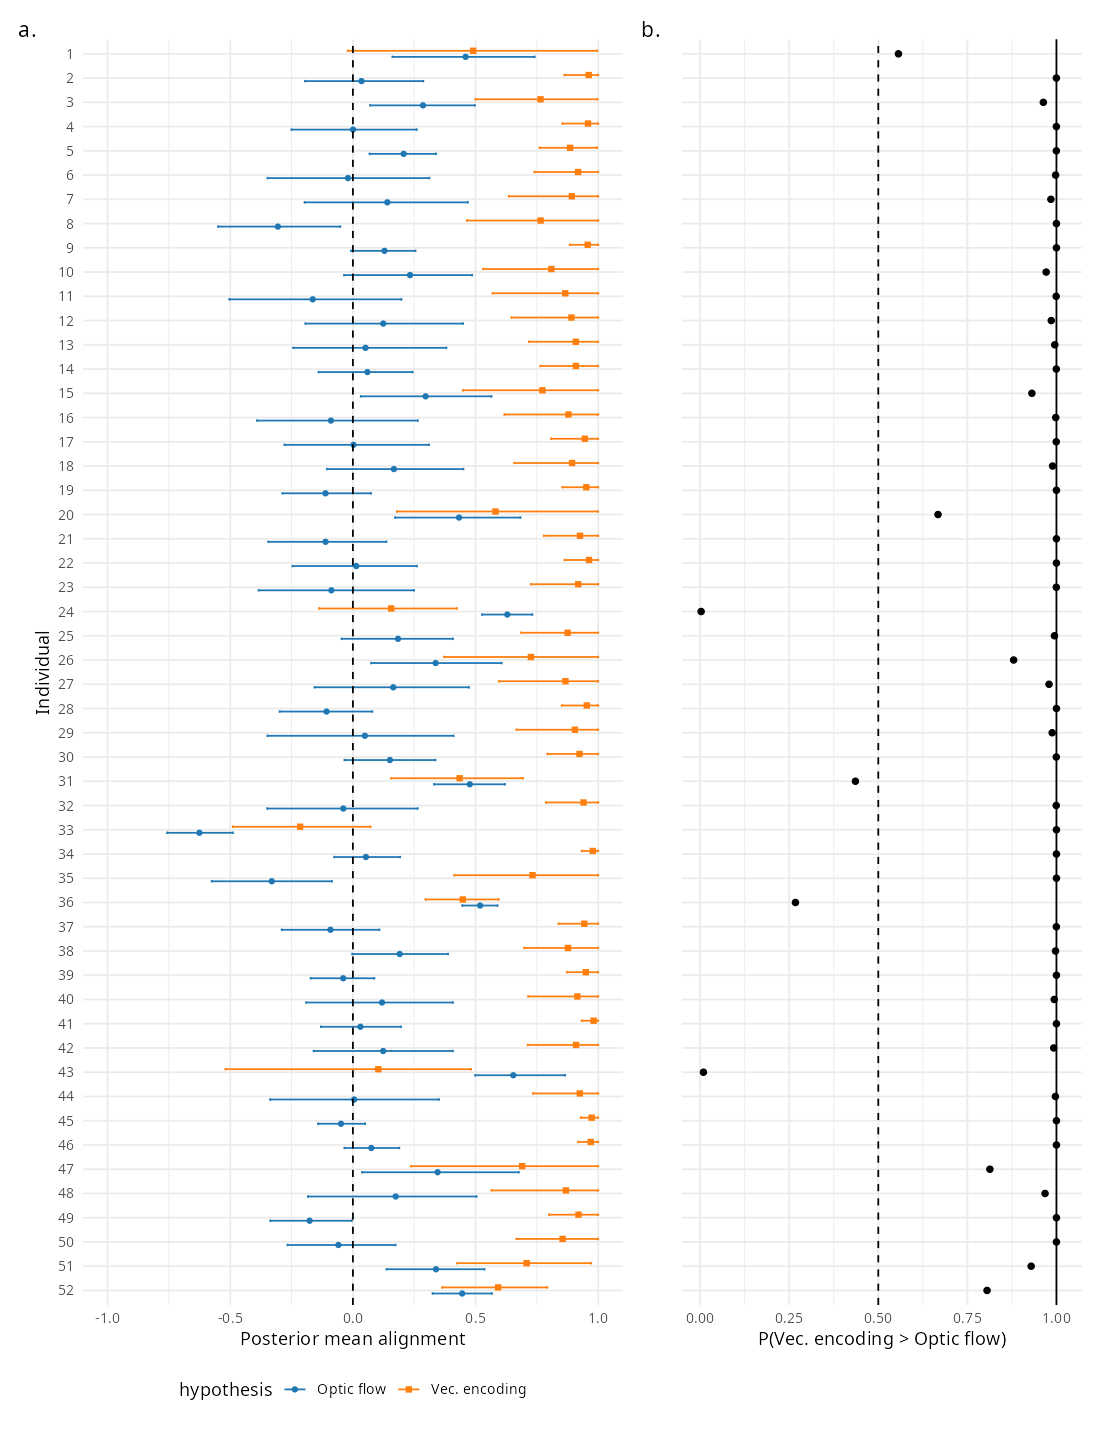

In [33]:
individual_alignment_table <- make_hyp_table(align_ind, "alignment")
print(individual_alignment_table)
save_figure(individual_dots(individual_alignment_table, "Posterior mean alignment", 0,
                            limits = c(-1, 1)),
  "locust_directional_alignment_individual_ab", 10, 13)


## Summary

The analysis fits the hierarchical two-component von Mises mixture as the
primary model and the hierarchical unimodal von Mises model as a controlled
baseline, compares the two with conditional step-level PSIS-LOO, and checks
the population- and individual-level fits with the predictive and hypothesis
figures above. The empirical support for optic flow versus vectorial
encoding is read from those results after the diagnostic gates have been
reviewed.

Animal offsets are zero for the population-level tests; the individual
checks retain them. Predictive density, mean log density at a fixed
theory-predicted heading, and weight-only directional alignment answer
different questions. In this reanalysis, posterior support is substantially
stronger for the lateral-turning prediction ($\pm\tfrac{\pi}{2}$) than
for the forward-marching prediction ($0$), consistent with the vectorial /
ring-attractor interpretation.
